## Introducción

Importar paquetes.

In [1]:
import time
from datetime import datetime
import pandas as pd
import re

import torch
import torch.nn as nn
import torch.nn.functional as actF

import torch_geometric.nn as pyg_nn
import torch_geometric.utils as pyg_utils

import networkx as nx
import numpy as np
import torch.optim as optim

import torch_geometric.transforms as T

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

/home/pedro/miniconda3/envs/envml/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cargar datos. Considero solamente datos de la subcuenca con punto de cierre en la estación de Florída.

In [2]:
data_folder = "../data/tscf_data/"

df_data_all = pd.read_parquet(data_folder+"SLC_all_data_2011_2022.parquet")
df_data_all = df_data_all.drop(columns=["[Florida (Puente Ruta 5)] Nivel de agua (h) [m]"]) # Drop nivel (= Caudal)
df_data_all = df_data_all.drop(columns=["[Florida] Precipitacion (P) [mm]"])

In [11]:
print(f"{df_data_all.index.min()}, {df_data_all.index.max()}")

2011-01-01 00:00:00, 2022-03-28 00:00:00


## Graph definition

### Test 1: Edge features

En este caso:
- Nodo = Estación de monitoreo
- Atributos del nodo = Variables medidas
- Vertices = Conexiones entre estaciones
- El grafo es dirigido

<img src="notebook_imgs/grafo1.jpg" width="50%">

In [3]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [4]:
stations_coords

,longitud,latitud
station,,
Florida (Puente Ruta 5),-56.20013,-34.06973
INIA Las Brujas,-56.34011,-34.65811
Cerro Colorado,-55.54943,-33.84908
La Cruz,-56.23712,-33.91546
Reboledo,-55.65021,-33.98643
San Gabriel,-55.88018,-34.02641
Sarandi Grande,-56.32750,-33.70884


In [5]:
# --- (2) Se define la conectividad del grafo ---

edge_index = torch.tensor([
    [1, 2, 3, 4, 5, 6],
    [0, 0, 0, 0, 0, 0]
], dtype=torch.long)
edge_index

tensor([[1, 2, 3, 4, 5, 6],
        [0, 0, 0, 0, 0, 0]])

In [6]:
def IDW_Calc(d, p=2):
    d = np.array(d, dtype=float)
    
    weights = 1 / (d ** p)
    weights /= weights.sum()
    
    return weights

In [7]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

weights = torch.tensor(IDW_Calc(distances))

# Normalize to [0,1]

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[0.0655],
        [0.0507],
        [0.4132],
        [0.0774],
        [0.2297],
        [0.1635]], dtype=torch.float64)

In [8]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [9]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [10]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [11]:
f"[{target_station}] {target_variable}"

'[Florida (Puente Ruta 5)] Caudal (Q) [m3/s]'

In [12]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [13]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [14]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    if (window == 1):

        for t in range(T - window):
            # Input
            x_window = x_all[:,t,:].clone()  # shape: [num_nodes, window, num_features]

            # Don't use target as input (set it to zero)
            x_window[:, target_feature_idx] = 0

            # Target timestep
            y_full = x_all[:,t, target_feature_idx]  # shape: [num_nodes]
            
            # If: 
            #   target_node_idx = None --> Predict all variables
            #   target_node_idx = idx --> Predict 'idx' variable
            if target_node_idx is not None:
                y = y_full[target_node_idx]  # shape: scalar
            else:
                y = y_full  # shape: [num_nodes]

            data = Data(
                x=x_window,
                edge_index=edge_index,
                edge_weight=edge_weight,
                y=y
            )

            data_list.append(data)
    
    else:
        for t in range(T - window):

            # Input window
            x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

            # Don't use target as input (set it to zero)
            x_window[:, :, target_feature_idx] = 0

            # Target timestep
            y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
            
            # If: 
            #   target_node_idx = None --> Predict all variables
            #   target_node_idx = idx --> Predict 'idx' variable
            if target_node_idx is not None:
                y = y_full[target_node_idx]  # shape: scalar
            else:
                y = y_full  # shape: [num_nodes]

            data = Data(
                x=x_window,
                edge_index=edge_index,
                edge_weight=edge_weight,
                y=y
            )

            data_list.append(data)

    return data_list

In [15]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 1

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3283
Graph train: Data(x=[7, 10], edge_index=[2, 6], y=9.52135378611274e-05, edge_weight=[6, 1])
Length test: 820
Graph test: Data(x=[7, 10], edge_index=[2, 6], y=0.00010925142851192504, edge_weight=[6, 1])


---------------------------------------------------------------------

### GNN Model Definition

In [16]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.fc = nn.Linear(
            gnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        #N, T, F = x.shape

        gnn_outputs = []

        x_t = x[:, :]  # [num_nodes, features]

        h_t = self.gconv1(
            x_t,
            edge_index=edge_index,
            edge_weight=edge_weight
        )  # [num_nodes, gnn_hidden]
        h_t = actF.relu(h_t)

        gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # Take last timestep
        h_last = h[:, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [17]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [ ]:
from sklearn.metrics import r2_score as nse_metric
import copy

num_features = dataset_train[0]["x"].shape[1]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    all_preds_inv = []
    all_targets_inv = []

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

        y_pred = target_prediction.reshape(-1, 1).detach().clone()
        y_true = data.y.reshape(-1, 1).detach().clone()

        target_prediction_inv = scalerY.inverse_transform(y_pred)
        target_true_inv = scalerY.inverse_transform(y_true)

        all_preds_inv.append(torch.from_numpy(target_prediction_inv))
        all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_train_loss / len(train_loader)

    return avg_loss, nse

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [240]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'v3/models/BasicGNN_Arq1_weigths.pth')
else:
    torch.save(model, 'v3/models/BasicGNN_Arq1_noweigths.pth')

Epoch [001/200] | Train Loss: 0.005526 | Train NSE: -2.49 | Test Loss: 0.001068 | Test NSE: -0.71
Epoch [002/200] | Train Loss: 0.002081 | Train NSE: -0.31 | Test Loss: 0.000917 | Test NSE: -0.59
Epoch [003/200] | Train Loss: 0.001843 | Train NSE: -0.16 | Test Loss: 0.000845 | Test NSE: -0.49
Epoch [004/200] | Train Loss: 0.001703 | Train NSE: -0.07 | Test Loss: 0.000788 | Test NSE: -0.41
Epoch [005/200] | Train Loss: 0.001605 | Train NSE: -0.01 | Test Loss: 0.000752 | Test NSE: -0.36
Epoch [006/200] | Train Loss: 0.001538 | Train NSE: 0.03 | Test Loss: 0.000731 | Test NSE: -0.33
Epoch [007/200] | Train Loss: 0.001492 | Train NSE: 0.06 | Test Loss: 0.000719 | Test NSE: -0.31
Epoch [008/200] | Train Loss: 0.001461 | Train NSE: 0.08 | Test Loss: 0.000717 | Test NSE: -0.31
Epoch [009/200] | Train Loss: 0.001440 | Train NSE: 0.09 | Test Loss: 0.000720 | Test NSE: -0.32
Epoch [010/200] | Train Loss: 0.001425 | Train NSE: 0.10 | Test Loss: 0.000727 | Test NSE: -0.33
Epoch [011/200] | Train L

In [241]:
from captum.attr import IntegratedGradients
import numpy as np
import torch
import matplotlib.pyplot as plt


def explain_with_captum(model, test_loader, variable_order):

    model.eval()
    all_attr = []

    print("\nRunning Captum Integrated Gradients...")

    for batch in test_loader:

        x = batch.x.clone().detach().requires_grad_(True)
        edge_index = batch.edge_index

        ########################################
        # IMPORTANT: wrap model correctly
        ########################################
        def forward_func(x_input):
            return model(x_input, edge_index)

        ig = IntegratedGradients(forward_func)

        attributions = ig.attribute(
            inputs=x
        )

        print("Batch attribution shape:", attributions.shape)

        attr = attributions.detach().cpu().numpy()
        attr = np.abs(attr)

        all_attr.append(attr)

    ##################################
    # Merge batches
    ##################################
    attr = np.concatenate(all_attr, axis=0)

    print("Merged attribution shape:", attr.shape)

    ##################################
    # Reduce feature dimension
    ##################################
    #attr = attr.mean(axis=0) 

    print("Reduced shape:", attr.shape)

    return attr

In [242]:
attr = explain_with_captum(model,test_loader, variable_order)


Running Captum Integrated Gradients...
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([364, 10])
Merged attribution shape: (5740, 10)
Reduced shape: (5740, 10)


In [243]:
def clean_list(lst):
    pattern = r'\([^)]*\)|\[[^\]]*\]|\{[^}]*\}|<[^>]*>'
    
    cleaned = []
    for s in lst:
        # remove bracket contents
        s = re.sub(pattern, '', s)
        # collapse multiple spaces + trim
        s = re.sub(r'\s+', ' ', s).strip()
        cleaned.append(s)
    
    return cleaned

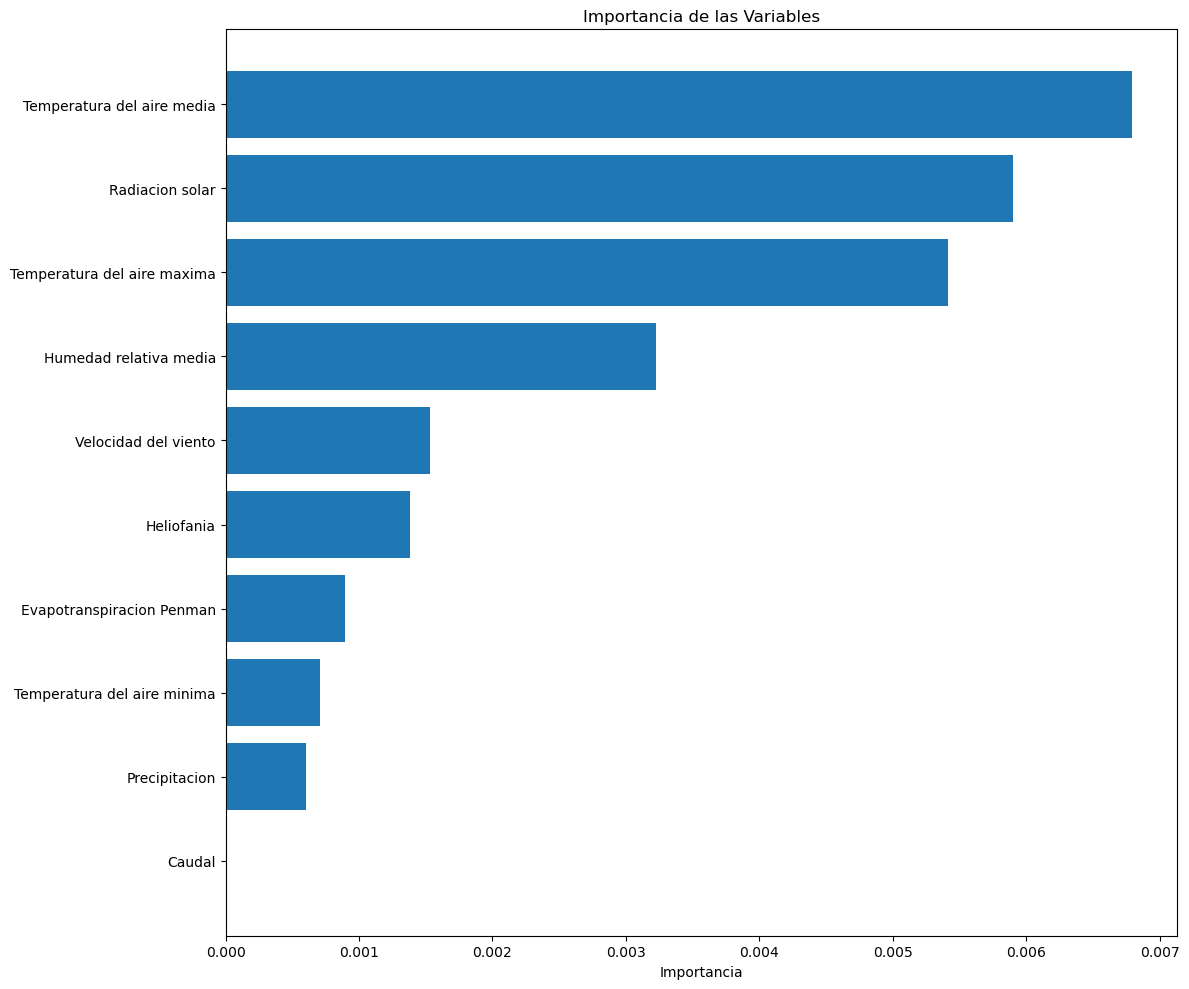

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

node_importance = attr.mean(axis=0)
var_names = clean_list(variable_order)

# sort (optional but often makes interpretation easier)
idx = np.argsort(node_importance)
node_importance = node_importance[idx]
var_names = np.array(var_names)[idx]

plt.figure(figsize=(12, 10))
plt.barh(np.arange(len(node_importance)), node_importance)

plt.yticks(np.arange(len(node_importance)), var_names)
plt.xlabel("Importancia")
plt.title("Importancia de las Variables")

plt.tight_layout()
plt.show()

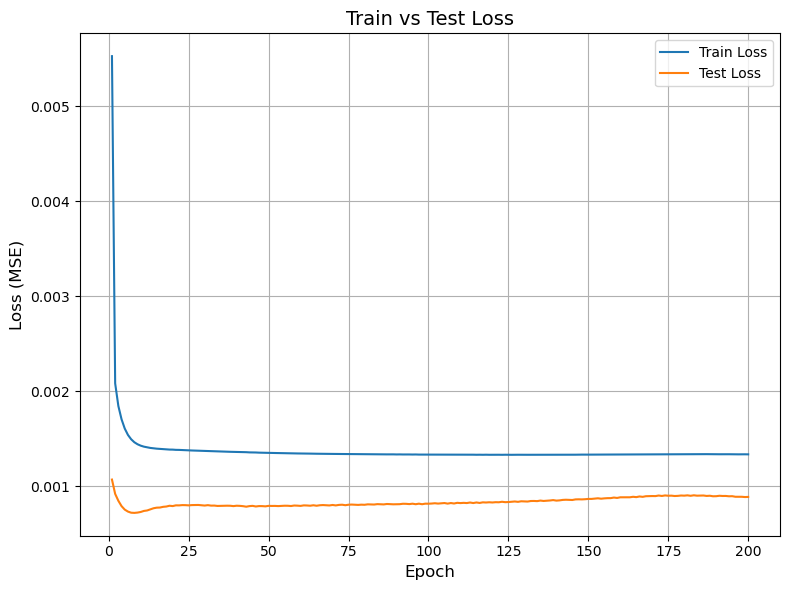

In [245]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

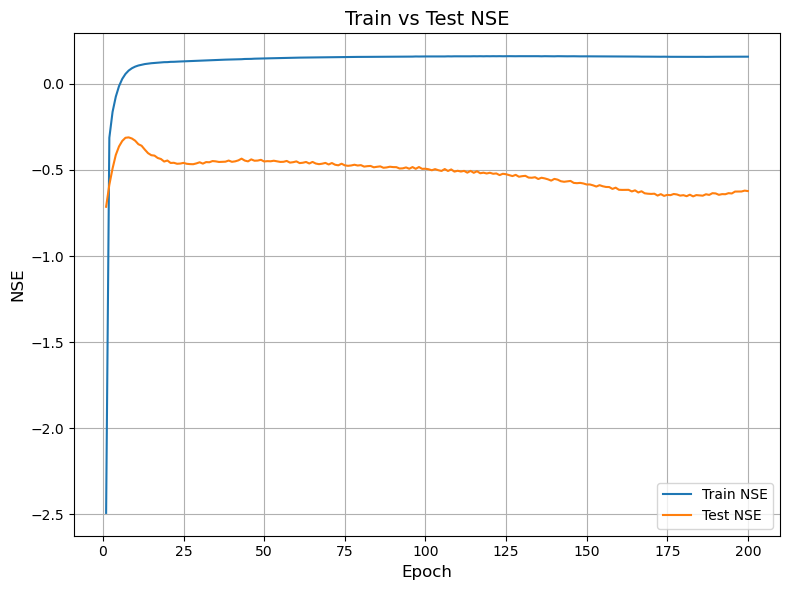

In [246]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [247]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

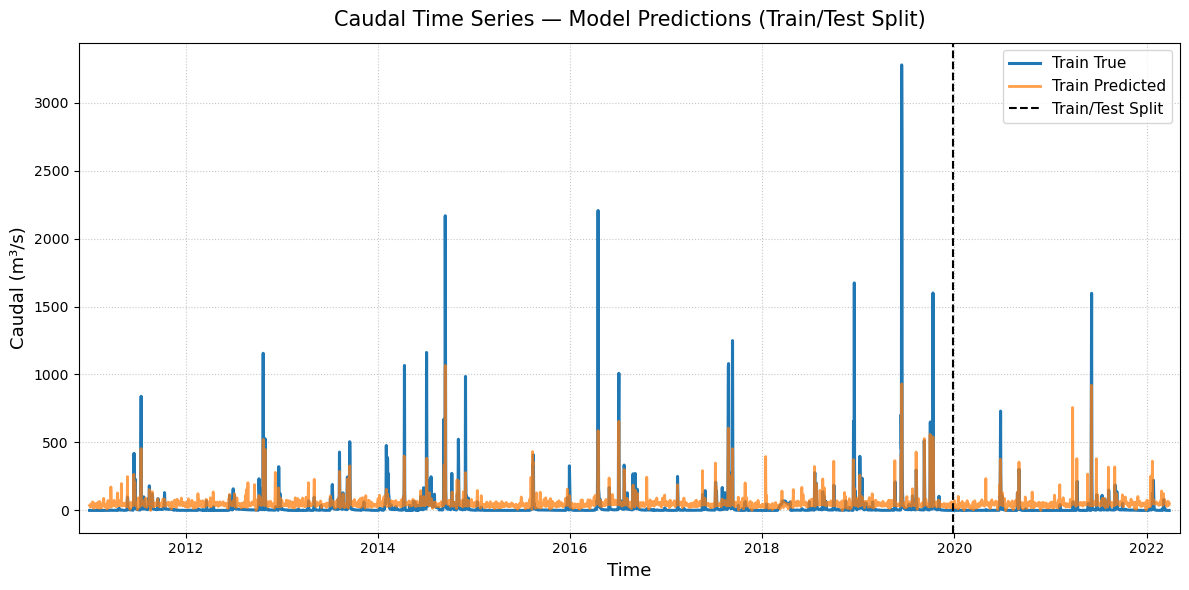

In [250]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

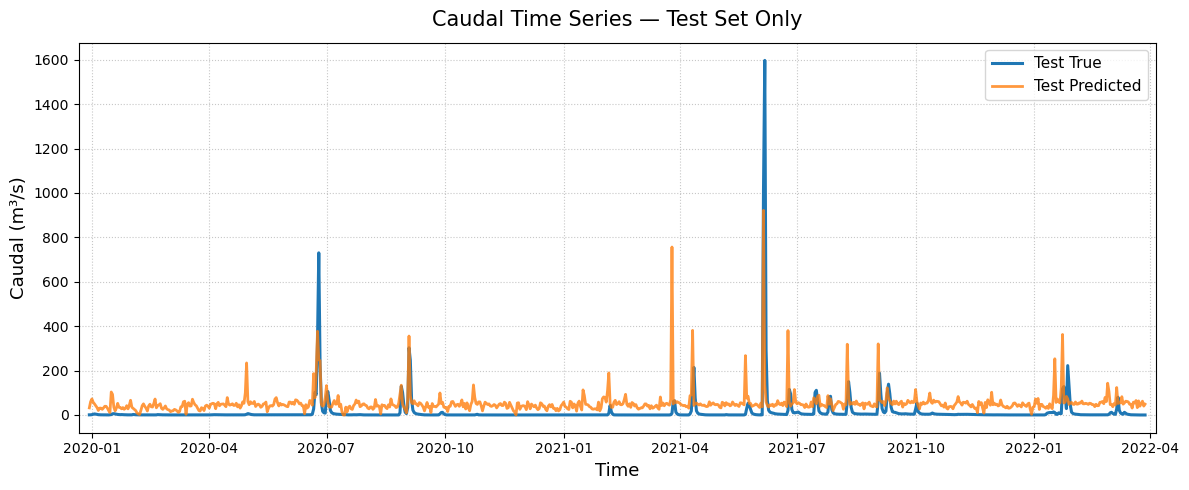

In [251]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()

plt.show()

-------

## Graph definition

### Test 1 v2: Edge features with stations distance (with weights)

En este caso:
- Nodo = Estación de monitoreo
- Atributos del nodo = Variables medidas
- Vertices = Conexiones entre estaciones
- Atributos del vertice = Distancia entre las estaciones conectadas
- El grafo es dirigido

<img src="notebook_imgs/grafo1.jpg" width="50%">

In [252]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [253]:
stations_coords

,longitud,latitud
station,,
Florida (Puente Ruta 5),-56.20013,-34.06973
INIA Las Brujas,-56.34011,-34.65811
Cerro Colorado,-55.54943,-33.84908
La Cruz,-56.23712,-33.91546
Reboledo,-55.65021,-33.98643
San Gabriel,-55.88018,-34.02641
Sarandi Grande,-56.32750,-33.70884


In [254]:
# --- (2) Se define la conectividad del grafo ---

edge_index = torch.tensor([
    [1, 2, 3, 4, 5, 6],
    [0, 0, 0, 0, 0, 0]
], dtype=torch.long)
edge_index

tensor([[1, 2, 3, 4, 5, 6],
        [0, 0, 0, 0, 0, 0]])

In [ ]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

weights = torch.tensor(IDW_Calc(distances))

# Normalize to [0,1]

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[0.1738],
        [0.0000],
        [1.0000],
        [0.2849],
        [0.8355],
        [0.7000]])

In [256]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [257]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [258]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [259]:
f"[{target_station}] {target_variable}"

'[Florida (Puente Ruta 5)] Caudal (Q) [m3/s]'

In [260]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [261]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [264]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    if (window == 1):

        for t in range(T - window):
            # Input
            x_window = x_all[:,t,:].clone()  # shape: [num_nodes, window, num_features]

            # Don't use target as input (set it to zero)
            x_window[:, target_feature_idx] = 0

            # Target timestep
            y_full = x_all[:,t, target_feature_idx]  # shape: [num_nodes]
            
            # If: 
            #   target_node_idx = None --> Predict all variables
            #   target_node_idx = idx --> Predict 'idx' variable
            if target_node_idx is not None:
                y = y_full[target_node_idx]  # shape: scalar
            else:
                y = y_full  # shape: [num_nodes]

            data = Data(
                x=x_window,
                edge_index=edge_index,
                edge_weight=edge_weight,
                y=y
            )

            data_list.append(data)
    
    else:
        for t in range(T - window):

            # Input window
            x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

            # Don't use target as input (set it to zero)
            x_window[:, :, target_feature_idx] = 0

            # Target timestep
            y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
            
            # If: 
            #   target_node_idx = None --> Predict all variables
            #   target_node_idx = idx --> Predict 'idx' variable
            if target_node_idx is not None:
                y = y_full[target_node_idx]  # shape: scalar
            else:
                y = y_full  # shape: [num_nodes]

            data = Data(
                x=x_window,
                edge_index=edge_index,
                edge_weight=edge_weight,
                y=y
            )

            data_list.append(data)

    return data_list

In [265]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 1

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3283
Graph train: Data(x=[7, 10], edge_index=[2, 6], y=9.52135378611274e-05, edge_weight=[6, 1])
Length test: 820
Graph test: Data(x=[7, 10], edge_index=[2, 6], y=0.00010925142851192504, edge_weight=[6, 1])


### GNN Model Definition

In [266]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [270]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[1]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    all_preds_inv = []
    all_targets_inv = []

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

        y_pred = target_prediction.reshape(-1, 1).detach().clone()
        y_true = data.y.reshape(-1, 1).detach().clone()

        target_prediction_inv = scalerY.inverse_transform(y_pred)
        target_true_inv = scalerY.inverse_transform(y_true)

        all_preds_inv.append(torch.from_numpy(target_prediction_inv))
        all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_train_loss / len(train_loader)

    return avg_loss, nse

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [278]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'v2/models/BasicGNN_Arq1_weigths.pth')
else:
    torch.save(model, 'v2/models/BasicGNN_Arq1_noweigths.pth')

Epoch [001/200] | Train Loss: 0.001424 | Train NSE: 0.10 | Test Loss: 0.000676 | Test NSE: -0.24
Epoch [002/200] | Train Loss: 0.001424 | Train NSE: 0.10 | Test Loss: 0.000678 | Test NSE: -0.24
Epoch [003/200] | Train Loss: 0.001424 | Train NSE: 0.10 | Test Loss: 0.000676 | Test NSE: -0.24
Epoch [004/200] | Train Loss: 0.001423 | Train NSE: 0.10 | Test Loss: 0.000676 | Test NSE: -0.24
Epoch [005/200] | Train Loss: 0.001423 | Train NSE: 0.10 | Test Loss: 0.000679 | Test NSE: -0.25
Epoch [006/200] | Train Loss: 0.001424 | Train NSE: 0.10 | Test Loss: 0.000678 | Test NSE: -0.24
Epoch [007/200] | Train Loss: 0.001423 | Train NSE: 0.10 | Test Loss: 0.000678 | Test NSE: -0.24
Epoch [008/200] | Train Loss: 0.001423 | Train NSE: 0.10 | Test Loss: 0.000677 | Test NSE: -0.24
Epoch [009/200] | Train Loss: 0.001423 | Train NSE: 0.10 | Test Loss: 0.000677 | Test NSE: -0.24
Epoch [010/200] | Train Loss: 0.001423 | Train NSE: 0.10 | Test Loss: 0.000680 | Test NSE: -0.25
Epoch [011/200] | Train Loss: 

In [279]:
from captum.attr import IntegratedGradients
import numpy as np
import torch
import matplotlib.pyplot as plt


def explain_with_captum(model, test_loader, variable_order):

    model.eval()
    all_attr = []

    print("\nRunning Captum Integrated Gradients...")

    for batch in test_loader:

        x = batch.x.clone().detach().requires_grad_(True)
        edge_index = batch.edge_index

        ########################################
        # IMPORTANT: wrap model correctly
        ########################################
        def forward_func(x_input):
            return model(x_input, edge_index)

        ig = IntegratedGradients(forward_func)

        attributions = ig.attribute(
            inputs=x
        )

        print("Batch attribution shape:", attributions.shape)

        attr = attributions.detach().cpu().numpy()
        attr = np.abs(attr)

        all_attr.append(attr)

    ##################################
    # Merge batches
    ##################################
    attr = np.concatenate(all_attr, axis=0)

    print("Merged attribution shape:", attr.shape)

    ##################################
    # Reduce feature dimension
    ##################################
    #attr = attr.mean(axis=0) 

    print("Reduced shape:", attr.shape)

    return attr

In [280]:
attr = explain_with_captum(model,test_loader, variable_order)


Running Captum Integrated Gradients...
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([364, 10])
Merged attribution shape: (5740, 10)
Reduced shape: (5740, 10)


In [281]:
def clean_list(lst):
    pattern = r'\([^)]*\)|\[[^\]]*\]|\{[^}]*\}|<[^>]*>'
    
    cleaned = []
    for s in lst:
        # remove bracket contents
        s = re.sub(pattern, '', s)
        # collapse multiple spaces + trim
        s = re.sub(r'\s+', ' ', s).strip()
        cleaned.append(s)
    
    return cleaned

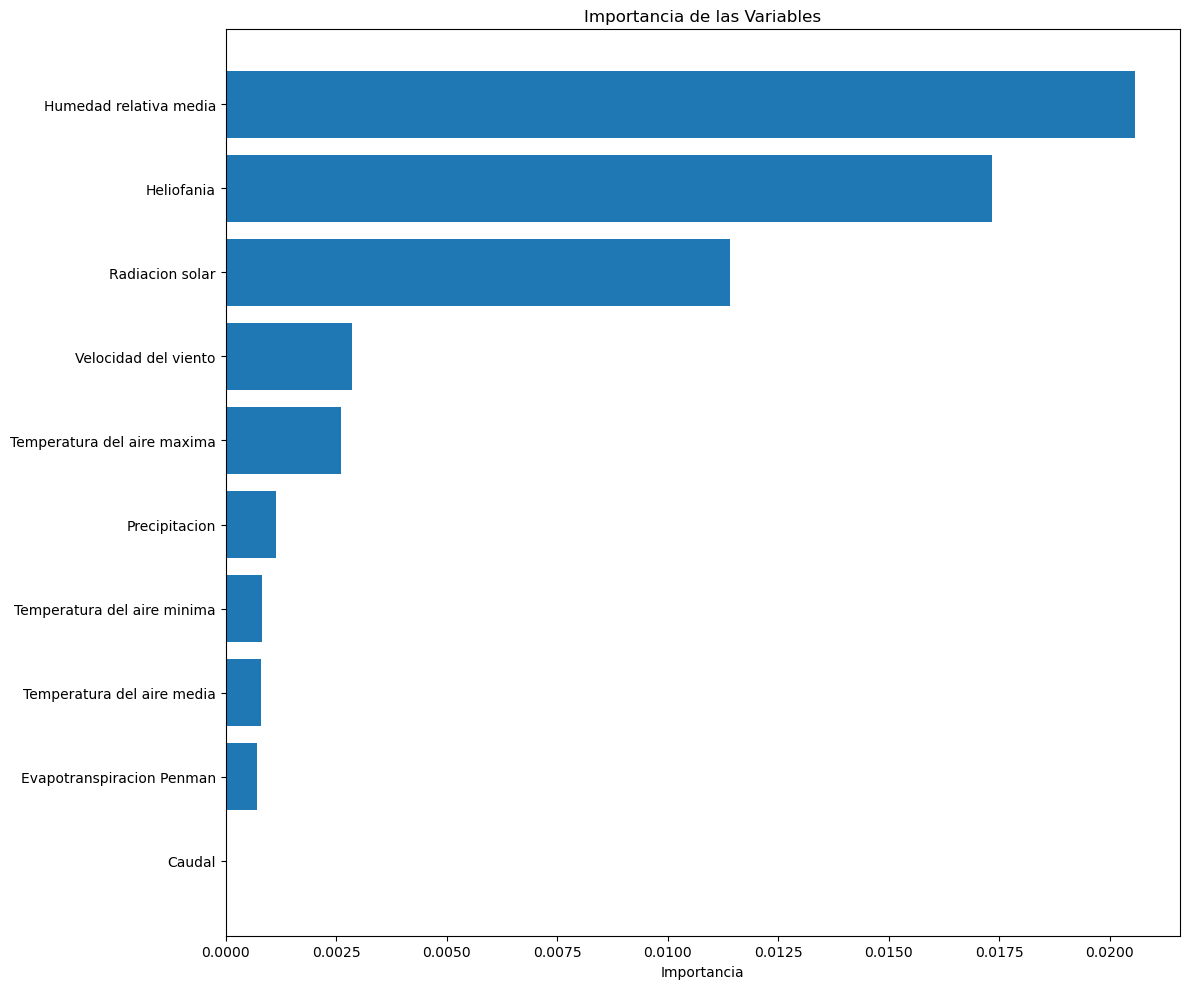

In [282]:
import numpy as np
import matplotlib.pyplot as plt

node_importance = attr.mean(axis=0)
var_names = clean_list(variable_order)

# sort (optional but often makes interpretation easier)
idx = np.argsort(node_importance)
node_importance = node_importance[idx]
var_names = np.array(var_names)[idx]

plt.figure(figsize=(12, 10))
plt.barh(np.arange(len(node_importance)), node_importance)

plt.yticks(np.arange(len(node_importance)), var_names)
plt.xlabel("Importancia")
plt.title("Importancia de las Variables")

plt.tight_layout()
plt.show()

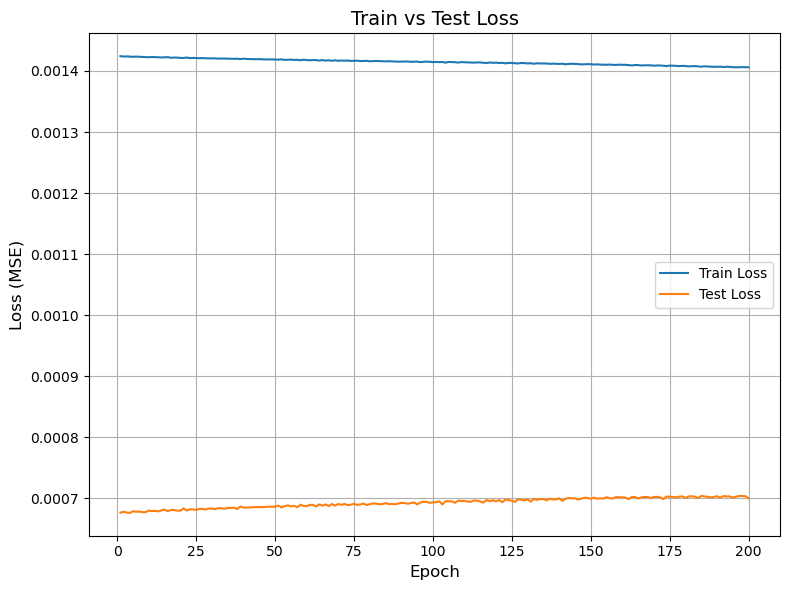

In [283]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

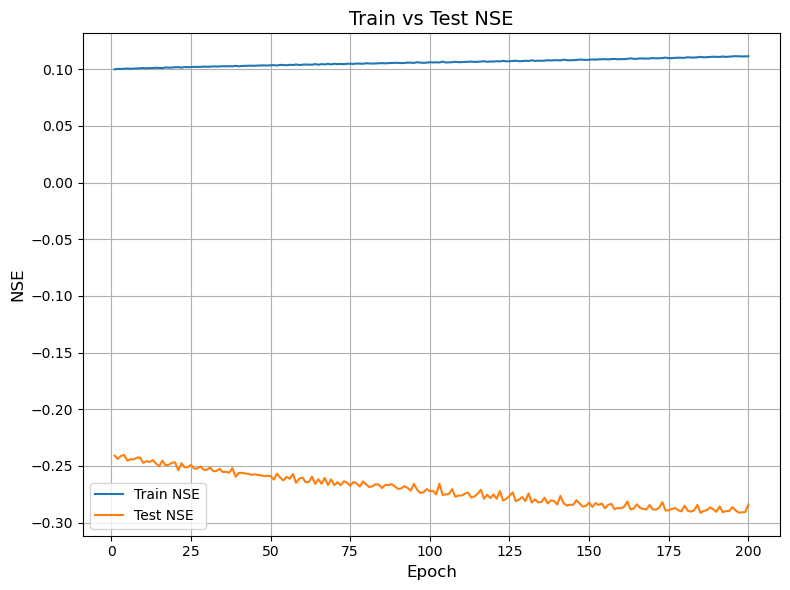

In [284]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [285]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

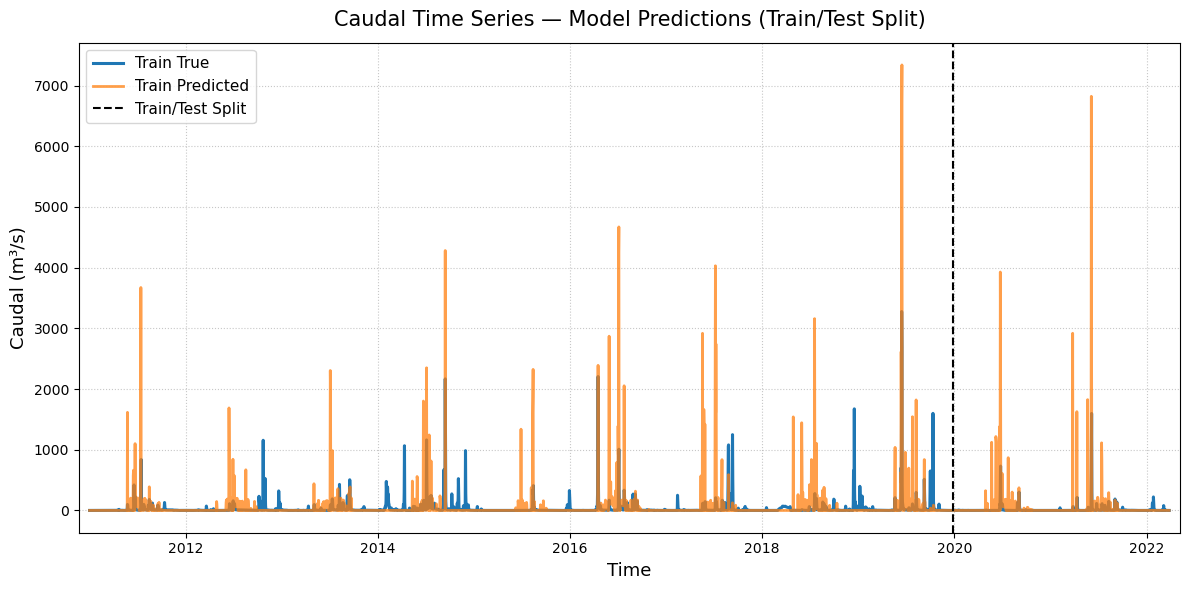

In [286]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

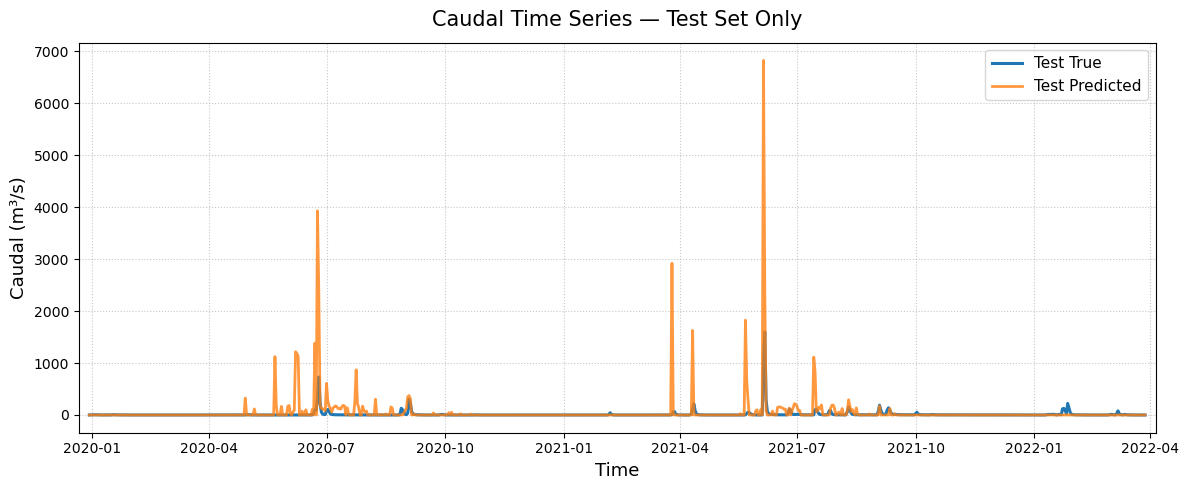

In [287]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()

plt.show()

## Graph definition

### Test 2: Edge features and self loop

En este caso:
- Nodo = Estación de monitoreo
- Atributos del nodo = Variables medidas
- Vertices = Conexiones entre estaciones
- Self loop = Caudal es input
- El grafo es dirigido

<img src="notebook_imgs/grafo1.jpg" width="50%">

In [288]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [289]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 1, 2, 3, 4, 5, 6],
    [0, 0, 0, 0, 0, 0, 0]
], dtype=torch.long)
edge_index

tensor([[0, 1, 2, 3, 4, 5, 6],
        [0, 0, 0, 0, 0, 0, 0]])

In [ ]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

weights = torch.tensor(IDW_Calc(distances))

# Normalize to [0,1]

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[1.0000],
        [0.1217],
        [0.0000],
        [0.9360],
        [0.2046],
        [0.6643],
        [0.5444]])

In [291]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [292]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [293]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [294]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [295]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [297]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    if (window == 1):

        for t in range(T - window):
            # Input
            x_window = x_all[:,t,:].clone()  # shape: [num_nodes, window, num_features]

            # Don't use target as input (set it to zero)
            #x_window[:, target_feature_idx] = 0

            # Target timestep
            y_full = x_all[:,t, target_feature_idx]  # shape: [num_nodes]
            
            # If: 
            #   target_node_idx = None --> Predict all variables
            #   target_node_idx = idx --> Predict 'idx' variable
            if target_node_idx is not None:
                y = y_full[target_node_idx]  # shape: scalar
            else:
                y = y_full  # shape: [num_nodes]

            data = Data(
                x=x_window,
                edge_index=edge_index,
                edge_weight=edge_weight,
                y=y
            )

            data_list.append(data)
    
    else:
        for t in range(T - window):

            # Input window
            x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

            # Don't use target as input (set it to zero)
            #x_window[:, :, target_feature_idx] = 0

            # Target timestep
            y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
            
            # If: 
            #   target_node_idx = None --> Predict all variables
            #   target_node_idx = idx --> Predict 'idx' variable
            if target_node_idx is not None:
                y = y_full[target_node_idx]  # shape: scalar
            else:
                y = y_full  # shape: [num_nodes]

            data = Data(
                x=x_window,
                edge_index=edge_index,
                edge_weight=edge_weight,
                y=y
            )

            data_list.append(data)

    return data_list

In [299]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 1

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3283
Graph train: Data(x=[7, 10], edge_index=[2, 7], y=9.52135378611274e-05, edge_weight=[7, 1])
Length test: 820
Graph test: Data(x=[7, 10], edge_index=[2, 7], y=0.00010925142851192504, edge_weight=[7, 1])


### GNN Model Definition

In [300]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [302]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[1]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    all_preds_inv = []
    all_targets_inv = []

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

        y_pred = target_prediction.reshape(-1, 1).detach().clone()
        y_true = data.y.reshape(-1, 1).detach().clone()

        target_prediction_inv = scalerY.inverse_transform(y_pred)
        target_true_inv = scalerY.inverse_transform(y_true)

        all_preds_inv.append(torch.from_numpy(target_prediction_inv))
        all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_train_loss / len(train_loader)

    return avg_loss, nse

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [304]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'v2/models/BasicGNN_Arq2_weigths.pth')
else:
    torch.save(model, 'v2/models/BasicGNN_Arq2_noweigths.pth')

Epoch [001/200] | Train Loss: 0.001039 | Train NSE: 0.34 | Test Loss: 0.000387 | Test NSE: 0.29
Epoch [002/200] | Train Loss: 0.000884 | Train NSE: 0.44 | Test Loss: 0.000328 | Test NSE: 0.40
Epoch [003/200] | Train Loss: 0.000734 | Train NSE: 0.54 | Test Loss: 0.000255 | Test NSE: 0.53
Epoch [004/200] | Train Loss: 0.000600 | Train NSE: 0.62 | Test Loss: 0.000204 | Test NSE: 0.63
Epoch [005/200] | Train Loss: 0.000476 | Train NSE: 0.70 | Test Loss: 0.000157 | Test NSE: 0.71
Epoch [006/200] | Train Loss: 0.000365 | Train NSE: 0.77 | Test Loss: 0.000117 | Test NSE: 0.78
Epoch [007/200] | Train Loss: 0.000273 | Train NSE: 0.83 | Test Loss: 0.000082 | Test NSE: 0.85
Epoch [008/200] | Train Loss: 0.000200 | Train NSE: 0.87 | Test Loss: 0.000055 | Test NSE: 0.90
Epoch [009/200] | Train Loss: 0.000145 | Train NSE: 0.91 | Test Loss: 0.000037 | Test NSE: 0.93
Epoch [010/200] | Train Loss: 0.000106 | Train NSE: 0.93 | Test Loss: 0.000026 | Test NSE: 0.95
Epoch [011/200] | Train Loss: 0.000078 |

In [305]:
from captum.attr import IntegratedGradients
import numpy as np
import torch
import matplotlib.pyplot as plt


def explain_with_captum(model, test_loader, variable_order):

    model.eval()
    all_attr = []

    print("\nRunning Captum Integrated Gradients...")

    for batch in test_loader:

        x = batch.x.clone().detach().requires_grad_(True)
        edge_index = batch.edge_index

        ########################################
        # IMPORTANT: wrap model correctly
        ########################################
        def forward_func(x_input):
            return model(x_input, edge_index)

        ig = IntegratedGradients(forward_func)

        attributions = ig.attribute(
            inputs=x
        )

        print("Batch attribution shape:", attributions.shape)

        attr = attributions.detach().cpu().numpy()
        attr = np.abs(attr)

        all_attr.append(attr)

    ##################################
    # Merge batches
    ##################################
    attr = np.concatenate(all_attr, axis=0)

    print("Merged attribution shape:", attr.shape)

    ##################################
    # Reduce feature dimension
    ##################################
    #attr = attr.mean(axis=0) 

    print("Reduced shape:", attr.shape)

    return attr

In [306]:
attr = explain_with_captum(model,test_loader, variable_order)


Running Captum Integrated Gradients...
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([364, 10])
Merged attribution shape: (5740, 10)
Reduced shape: (5740, 10)


In [307]:
def clean_list(lst):
    pattern = r'\([^)]*\)|\[[^\]]*\]|\{[^}]*\}|<[^>]*>'
    
    cleaned = []
    for s in lst:
        # remove bracket contents
        s = re.sub(pattern, '', s)
        # collapse multiple spaces + trim
        s = re.sub(r'\s+', ' ', s).strip()
        cleaned.append(s)
    
    return cleaned

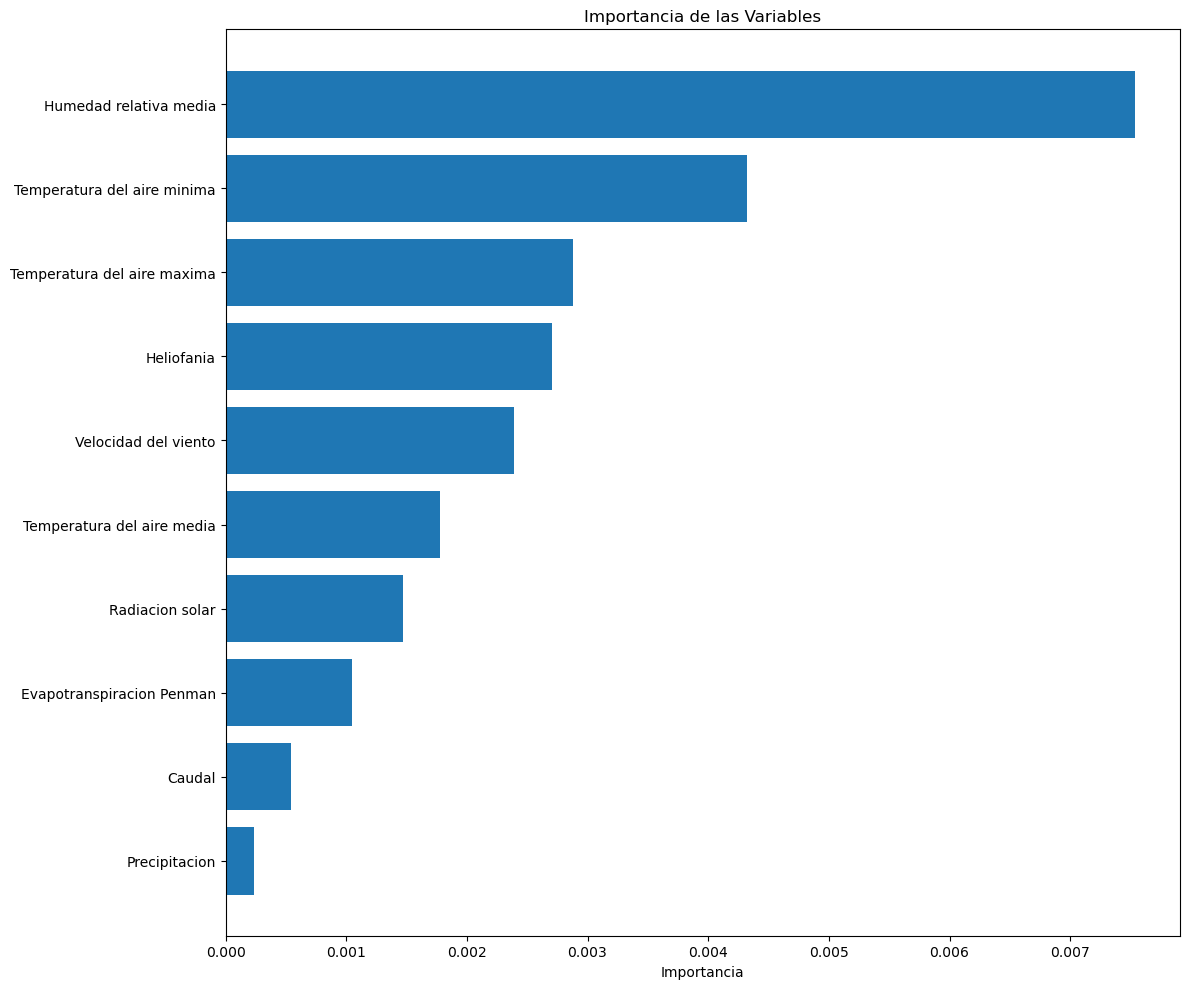

In [308]:
import numpy as np
import matplotlib.pyplot as plt

node_importance = attr.mean(axis=0)
var_names = clean_list(variable_order)

# sort (optional but often makes interpretation easier)
idx = np.argsort(node_importance)
node_importance = node_importance[idx]
var_names = np.array(var_names)[idx]

plt.figure(figsize=(12, 10))
plt.barh(np.arange(len(node_importance)), node_importance)

plt.yticks(np.arange(len(node_importance)), var_names)
plt.xlabel("Importancia")
plt.title("Importancia de las Variables")

plt.tight_layout()
plt.show()

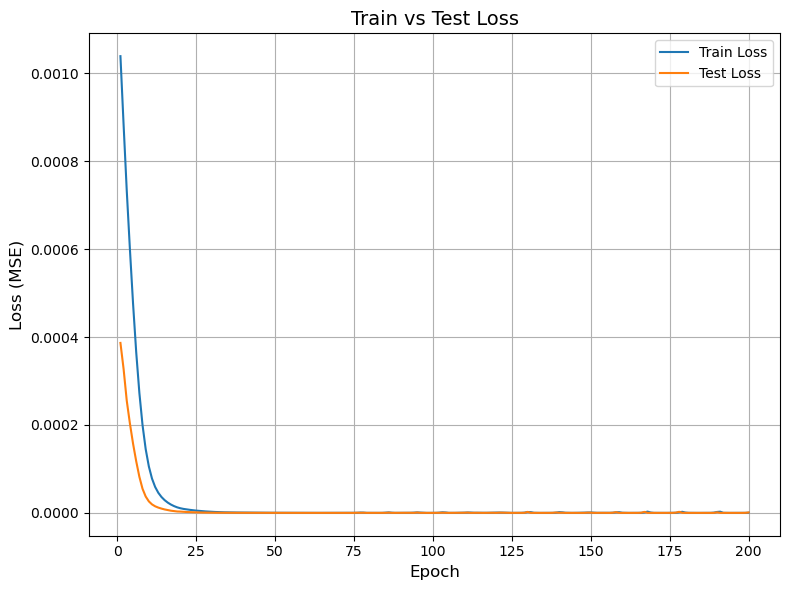

In [309]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

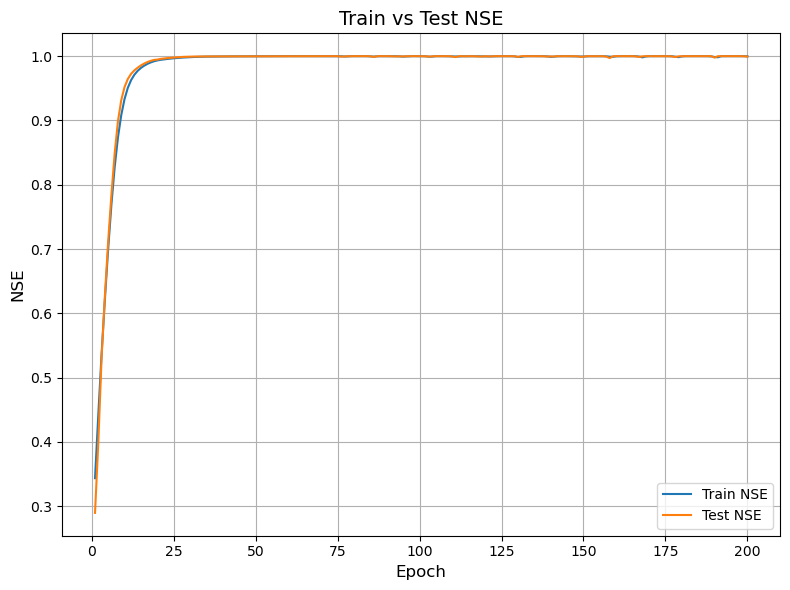

In [310]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [311]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

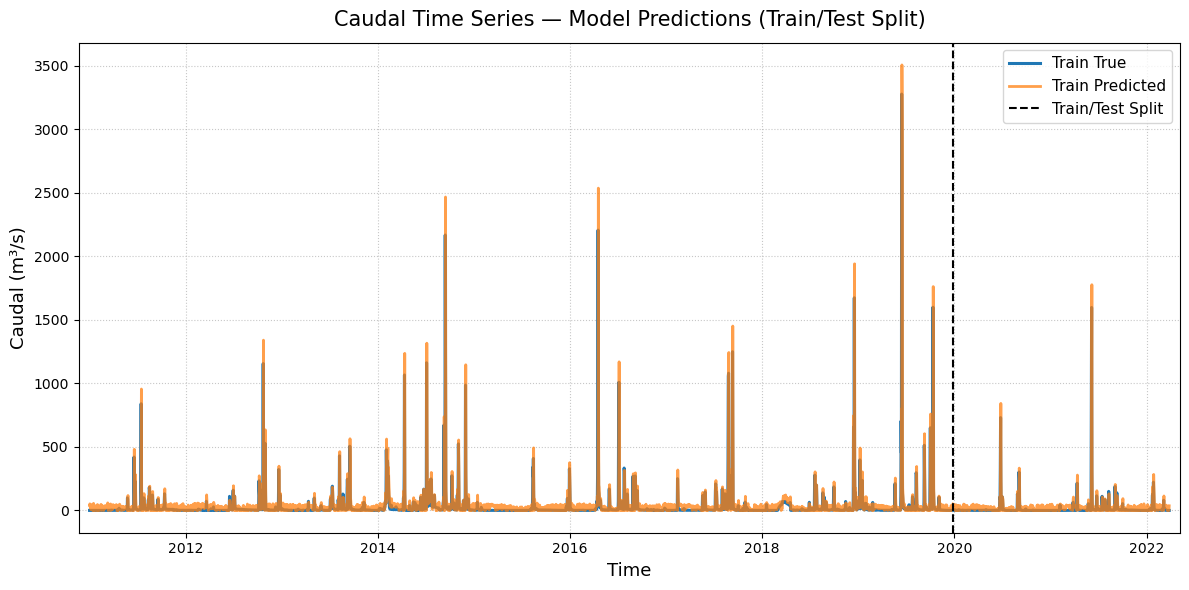

In [312]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

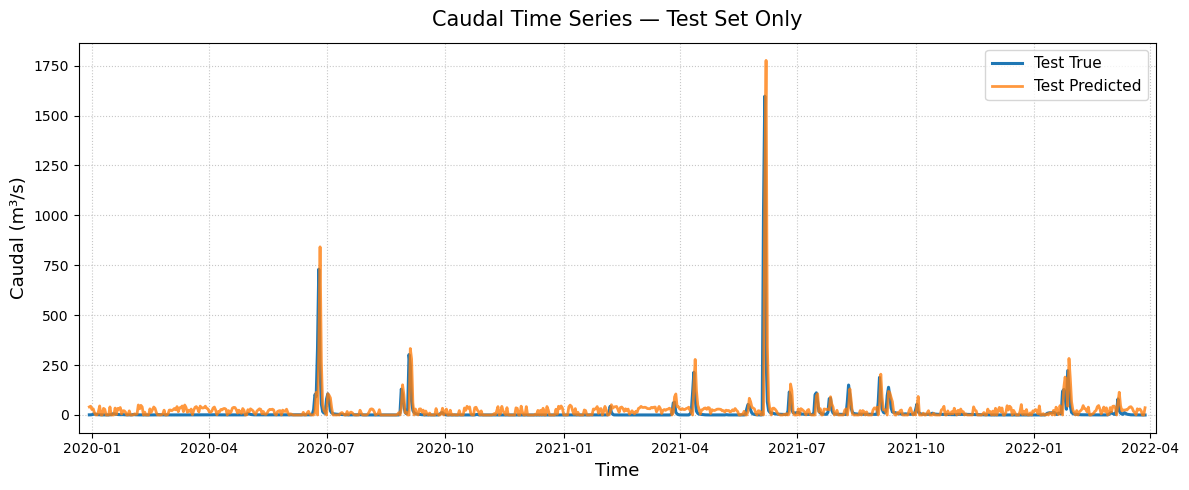

In [313]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()

plt.show()

## Graph Definition

### Test 2 v2: Edge features with self loop and stations distance (with weights)

In [90]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [91]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 1, 2, 3, 4, 5, 6, 7],
    [0, 0, 0, 0, 0, 0, 0, 0]
], dtype=torch.long)
edge_index

tensor([[0, 1, 2, 3, 4, 5, 6, 7],
        [0, 0, 0, 0, 0, 0, 0, 0]])

In [ ]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----
weights = torch.tensor(IDW_Calc(distances))

# Normalize to [0,1]

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[1.0000],
        [0.0880],
        [0.0000],
        [0.9996],
        [0.8825],
        [0.1538],
        [0.5850],
        [0.4630]])

In [93]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [94]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [95]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [96]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [97]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [98]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        # Self loop --> Use target as input (don't make feature zeros!)
        #x_window[:, :, target_feature_idx] = 0

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [99]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[8, 36, 10], edge_index=[2, 8], y=4.089299181941897e-05, edge_weight=[8, 1])
Length test: 785
Graph test: Data(x=[8, 36, 10], edge_index=[2, 8], y=0.0004632504715118557, edge_weight=[8, 1])


### GNN Model Definition

In [100]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [101]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [102]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

    return total_train_loss / len(train_loader)

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [301]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'models/BasicGNN_Arq2_weigths.pth')
else:
    torch.save(model, 'models/BasicGNN_Arq2_noweigths.pth')

Epoch [001/200] | Train Loss: 0.001855 | Test Loss: 0.000816 | Test NSE: -0.46
Epoch [002/200] | Train Loss: 0.001614 | Test Loss: 0.000739 | Test NSE: -0.33
Epoch [003/200] | Train Loss: 0.001547 | Test Loss: 0.000672 | Test NSE: -0.21
Epoch [004/200] | Train Loss: 0.001477 | Test Loss: 0.000609 | Test NSE: -0.10
Epoch [005/200] | Train Loss: 0.001403 | Test Loss: 0.000551 | Test NSE: 0.00
Epoch [006/200] | Train Loss: 0.001323 | Test Loss: 0.000500 | Test NSE: 0.09
Epoch [007/200] | Train Loss: 0.001237 | Test Loss: 0.000459 | Test NSE: 0.17
Epoch [008/200] | Train Loss: 0.001140 | Test Loss: 0.000433 | Test NSE: 0.21
Epoch [009/200] | Train Loss: 0.001021 | Test Loss: 0.000440 | Test NSE: 0.20
Epoch [010/200] | Train Loss: 0.000939 | Test Loss: 0.000465 | Test NSE: 0.16
Epoch [011/200] | Train Loss: 0.000895 | Test Loss: 0.000451 | Test NSE: 0.18
Epoch [012/200] | Train Loss: 0.000858 | Test Loss: 0.000443 | Test NSE: 0.19
Epoch [013/200] | Train Loss: 0.000830 | Test Loss: 0.000436

In [104]:
import torch
import torch.serialization

torch.serialization.add_safe_globals([BasicGNN])

model = torch.load(
    "models/Arq2_weight/BasicGNN_Arq2_weigths.pth",
    map_location="cpu",
    weights_only=False
)


# Set evaluation mode
model.eval()

print("Model loaded successfully.")

Model loaded successfully.


In [105]:
from captum.attr import IntegratedGradients

model.eval()

data = dataset_test[0]

x = data.x.clone().requires_grad_(True)
edge_index = data.edge_index

target_node = target_node_idx


def model_forward(x):
    out = model(x, edge_index)

    # Make sure output is at least 1D
    if out.dim() == 2:
        out = out[target_node, 0]

    elif out.dim() == 1:
        out = out[target_node]

    elif out.dim() == 0:
        out = out

    # IMPORTANT: return as 1D tensor
    return out.unsqueeze(0)


ig = IntegratedGradients(model_forward)

baseline = torch.zeros_like(x)

attributions = ig.attribute(
    x,
    baselines=baseline
)

In [106]:
import numpy as np

attr = attributions.detach().cpu().numpy()

node_importance = np.sum(
    np.abs(attr),
    axis=(1, 2)
)

node_importance /= node_importance.max()

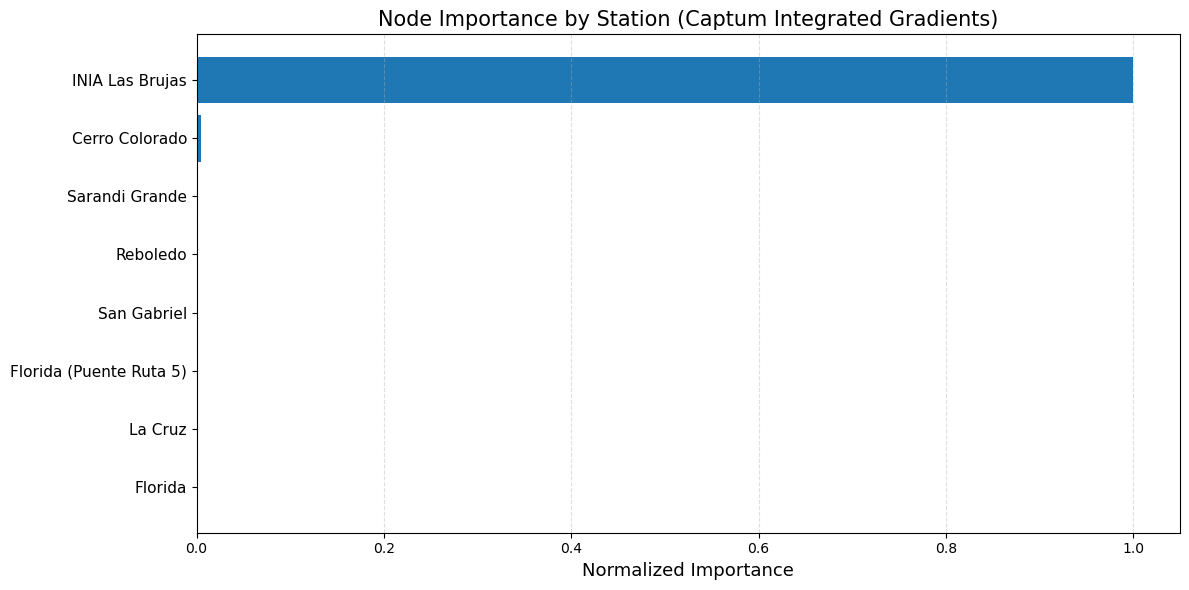

In [107]:
import matplotlib.pyplot as plt
import numpy as np

# Convert to numpy if needed
node_importance = np.array(node_importance)

# Sort nodes by importance
sorted_idx = np.argsort(node_importance)

sorted_importance = node_importance[sorted_idx]
sorted_stations = np.array(station_order)[sorted_idx]

# Plot
plt.figure(figsize=(12, 6))

bars = plt.barh(
    range(len(sorted_importance)),
    sorted_importance,
    alpha=0.9
)

# Highlight top 3 stations
top_k = 3
for i in range(1, top_k + 1):
    bars[-i].set_alpha(1.0)

plt.yticks(
    range(len(sorted_stations)),
    sorted_stations,
    fontsize=11
)

plt.xlabel(
    "Normalized Importance",
    fontsize=13
)

plt.title(
    "Node Importance by Station (Captum Integrated Gradients)",
    fontsize=15
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

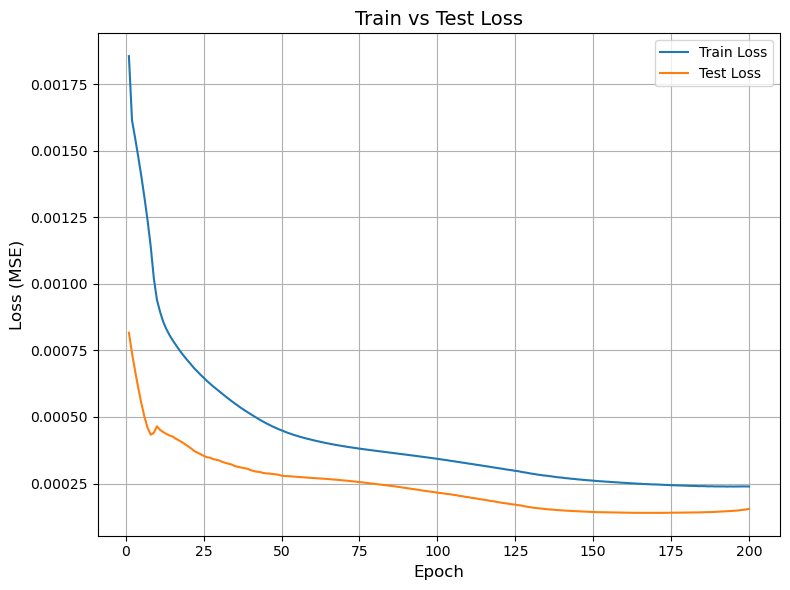

In [302]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

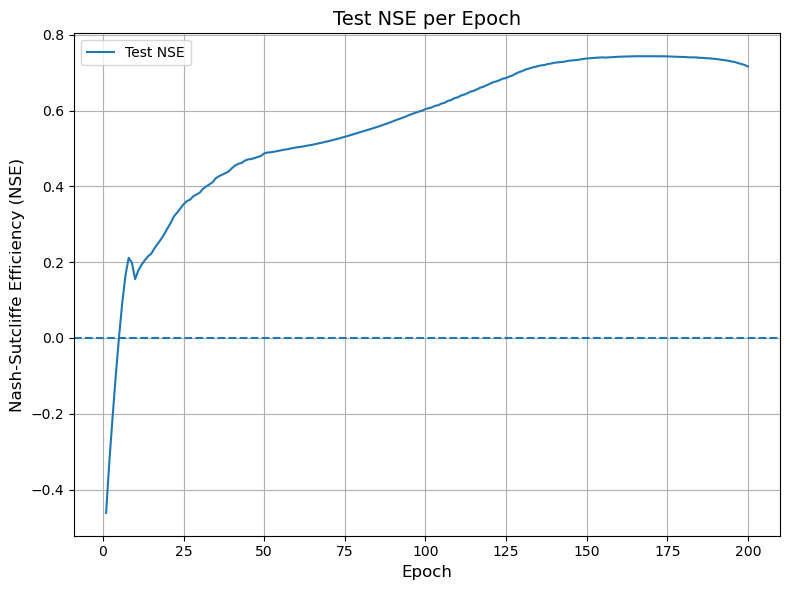

In [303]:
plt.figure(figsize=(8,6))

plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Nash-Sutcliffe Efficiency (NSE)", fontsize=12)
plt.title("Test NSE per Epoch", fontsize=14)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.axhline(0, linestyle="--")  # useful NSE reference

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [304]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

In [306]:
nse_metric(y_true_test, y_pred_test)

0.7160024095306304

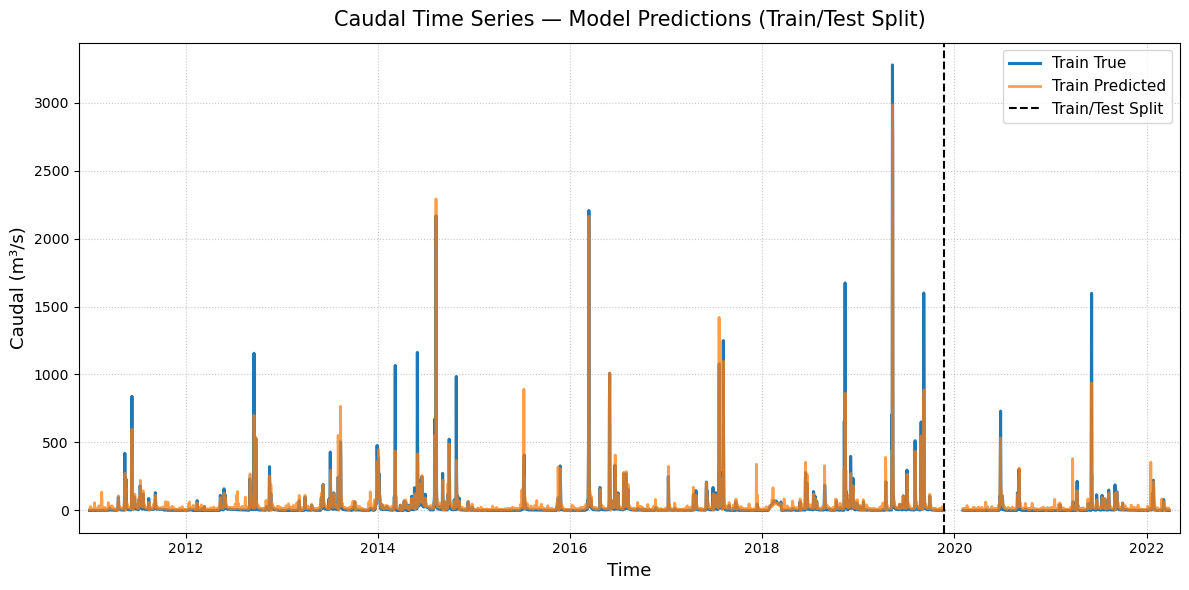

In [305]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

## Graph Definition

### Test 3: Sugerencia Angela

<img src="notebook_imgs/grafo1.jpg" width="50%">

In [31]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [32]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [2, 3, 4, 5, 6, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 2, 3, 4, 5, 6]
], dtype=torch.long)
edge_index

tensor([[2, 3, 4, 5, 6, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 2, 3, 4, 5, 6]])

In [33]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

weights = torch.tensor(IDW_Calc(distances))

# Normalize to [0,1]

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[0.0546],
        [0.2744],
        [0.0833],
        [0.2472],
        [0.1759],
        [0.0201],
        [0.0458],
        [0.0278],
        [0.0422],
        [0.0286]], dtype=torch.float64)

In [34]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [35]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [36]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [37]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [38]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [39]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    if (window == 1):

        for t in range(T - window):
            # Input
            x_window = x_all[:,t,:].clone()  # shape: [num_nodes, window, num_features]

            # Don't use target as input (set it to zero)
            x_window[:, target_feature_idx] = 0

            # Target timestep
            y_full = x_all[:,t, target_feature_idx]  # shape: [num_nodes]
            
            # If: 
            #   target_node_idx = None --> Predict all variables
            #   target_node_idx = idx --> Predict 'idx' variable
            if target_node_idx is not None:
                y = y_full[target_node_idx]  # shape: scalar
            else:
                y = y_full  # shape: [num_nodes]

            data = Data(
                x=x_window,
                edge_index=edge_index,
                edge_weight=edge_weight,
                y=y
            )

            data_list.append(data)
    
    else:
        for t in range(T - window):

            # Input window
            x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

            # Don't use target as input (set it to zero)
            x_window[:, :, target_feature_idx] = 0

            # Target timestep
            y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
            
            # If: 
            #   target_node_idx = None --> Predict all variables
            #   target_node_idx = idx --> Predict 'idx' variable
            if target_node_idx is not None:
                y = y_full[target_node_idx]  # shape: scalar
            else:
                y = y_full  # shape: [num_nodes]

            data = Data(
                x=x_window,
                edge_index=edge_index,
                edge_weight=edge_weight,
                y=y
            )

            data_list.append(data)

    return data_list

In [40]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 1

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3283
Graph train: Data(x=[7, 10], edge_index=[2, 10], y=9.52135378611274e-05, edge_weight=[10, 1])
Length test: 820
Graph test: Data(x=[7, 10], edge_index=[2, 10], y=0.00010925142851192504, edge_weight=[10, 1])


### Modelo

In [41]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [43]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[1]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    all_preds_inv = []
    all_targets_inv = []

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

        y_pred = target_prediction.reshape(-1, 1).detach().clone()
        y_true = data.y.reshape(-1, 1).detach().clone()

        target_prediction_inv = scalerY.inverse_transform(y_pred)
        target_true_inv = scalerY.inverse_transform(y_true)

        all_preds_inv.append(torch.from_numpy(target_prediction_inv))
        all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_train_loss / len(train_loader)

    return avg_loss, nse

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [ ]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'v2/models/BasicGNN_Arq2_weigths.pth')
else:
    torch.save(model, 'v2/models/BasicGNN_Arq2_noweigths.pth')

Epoch [001/200] | Train Loss: 0.001429 | Train NSE: 0.10 | Test Loss: 0.000655 | Test NSE: -0.20
Epoch [002/200] | Train Loss: 0.001407 | Train NSE: 0.11 | Test Loss: 0.000689 | Test NSE: -0.26
Epoch [003/200] | Train Loss: 0.001404 | Train NSE: 0.11 | Test Loss: 0.000708 | Test NSE: -0.30
Epoch [004/200] | Train Loss: 0.001403 | Train NSE: 0.11 | Test Loss: 0.000719 | Test NSE: -0.32
Epoch [005/200] | Train Loss: 0.001402 | Train NSE: 0.11 | Test Loss: 0.000726 | Test NSE: -0.33
Epoch [006/200] | Train Loss: 0.001401 | Train NSE: 0.11 | Test Loss: 0.000733 | Test NSE: -0.34
Epoch [007/200] | Train Loss: 0.001401 | Train NSE: 0.11 | Test Loss: 0.000736 | Test NSE: -0.35
Epoch [008/200] | Train Loss: 0.001401 | Train NSE: 0.11 | Test Loss: 0.000739 | Test NSE: -0.35
Epoch [009/200] | Train Loss: 0.001401 | Train NSE: 0.11 | Test Loss: 0.000740 | Test NSE: -0.36
Epoch [010/200] | Train Loss: 0.001400 | Train NSE: 0.11 | Test Loss: 0.000742 | Test NSE: -0.36
Epoch [011/200] | Train Loss: 

RuntimeError: Parent directory models does not exist.

In [45]:
from captum.attr import IntegratedGradients
import numpy as np
import torch
import matplotlib.pyplot as plt


def explain_with_captum(model, test_loader, variable_order):

    model.eval()
    all_attr = []

    print("\nRunning Captum Integrated Gradients...")

    for batch in test_loader:

        x = batch.x.clone().detach().requires_grad_(True)
        edge_index = batch.edge_index

        ########################################
        # IMPORTANT: wrap model correctly
        ########################################
        def forward_func(x_input):
            return model(x_input, edge_index)

        ig = IntegratedGradients(forward_func)

        attributions = ig.attribute(
            inputs=x
        )

        print("Batch attribution shape:", attributions.shape)

        attr = attributions.detach().cpu().numpy()
        attr = np.abs(attr)

        all_attr.append(attr)

    ##################################
    # Merge batches
    ##################################
    attr = np.concatenate(all_attr, axis=0)

    print("Merged attribution shape:", attr.shape)

    ##################################
    # Reduce feature dimension
    ##################################
    #attr = attr.mean(axis=0) 

    print("Reduced shape:", attr.shape)

    return attr

In [46]:
attr = explain_with_captum(model,test_loader, variable_order)


Running Captum Integrated Gradients...
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([364, 10])
Merged attribution shape: (5740, 10)
Reduced shape: (5740, 10)


In [47]:
def clean_list(lst):
    pattern = r'\([^)]*\)|\[[^\]]*\]|\{[^}]*\}|<[^>]*>'
    
    cleaned = []
    for s in lst:
        # remove bracket contents
        s = re.sub(pattern, '', s)
        # collapse multiple spaces + trim
        s = re.sub(r'\s+', ' ', s).strip()
        cleaned.append(s)
    
    return cleaned

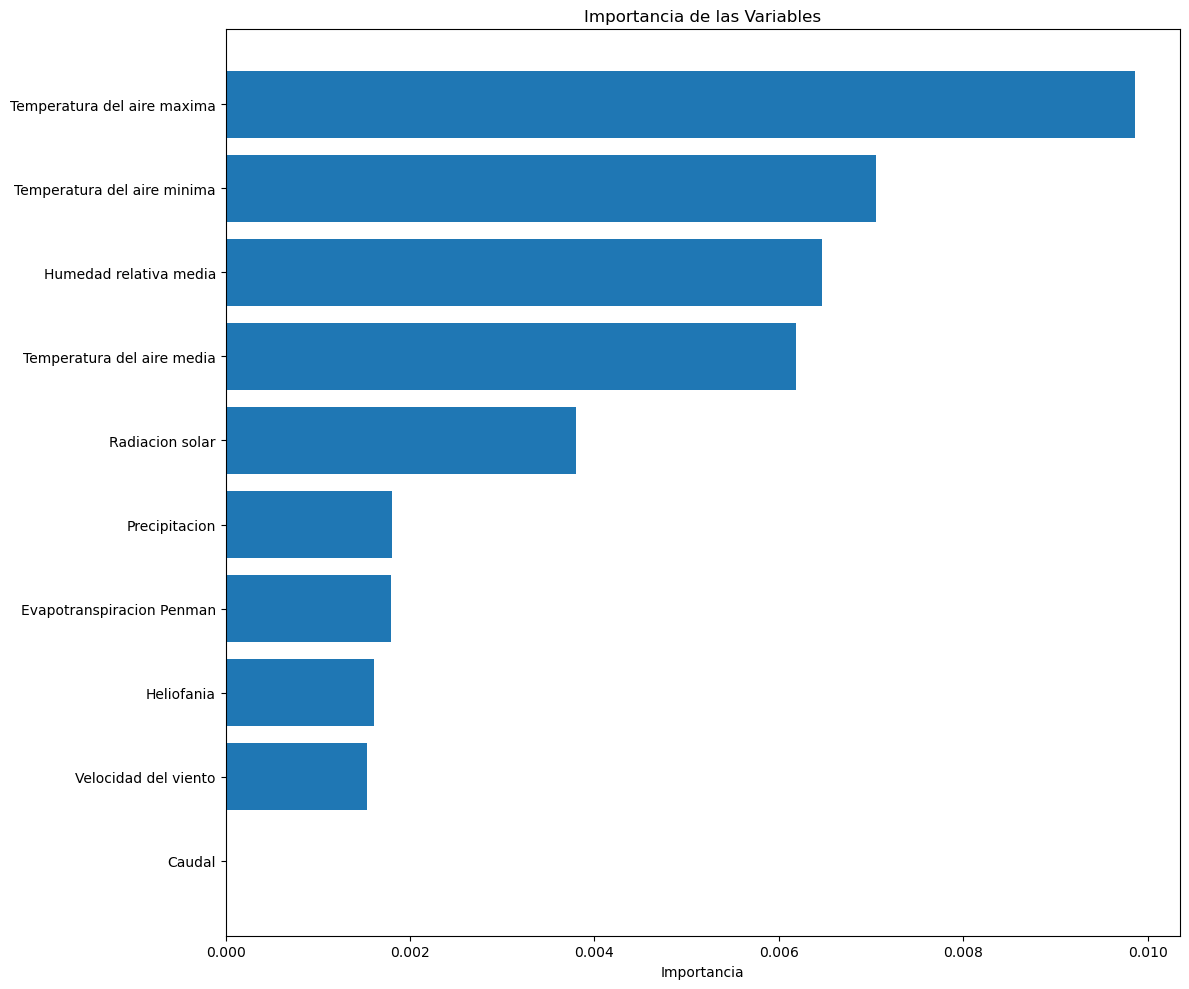

In [48]:
import numpy as np
import matplotlib.pyplot as plt

node_importance = attr.mean(axis=0)
var_names = clean_list(variable_order)

# sort (optional but often makes interpretation easier)
idx = np.argsort(node_importance)
node_importance = node_importance[idx]
var_names = np.array(var_names)[idx]

plt.figure(figsize=(12, 10))
plt.barh(np.arange(len(node_importance)), node_importance)

plt.yticks(np.arange(len(node_importance)), var_names)
plt.xlabel("Importancia")
plt.title("Importancia de las Variables")

plt.tight_layout()
plt.show()

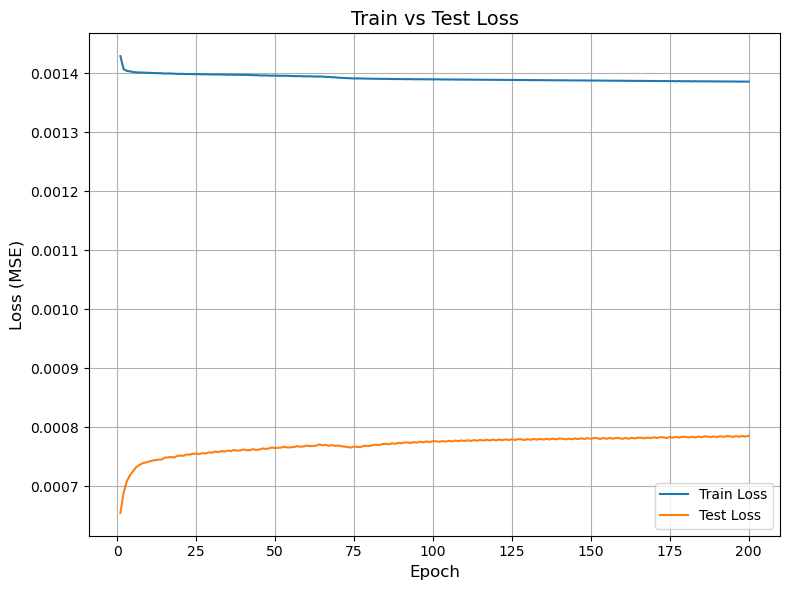

In [49]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

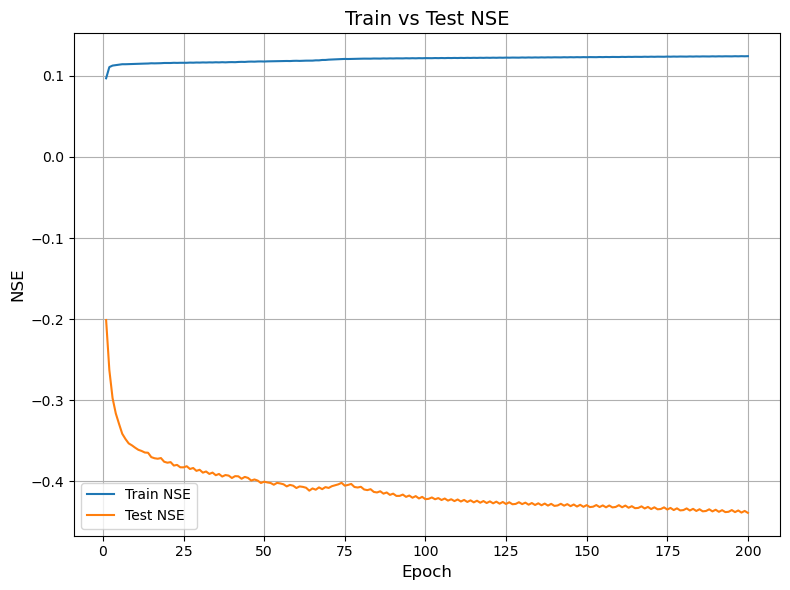

In [50]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [51]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

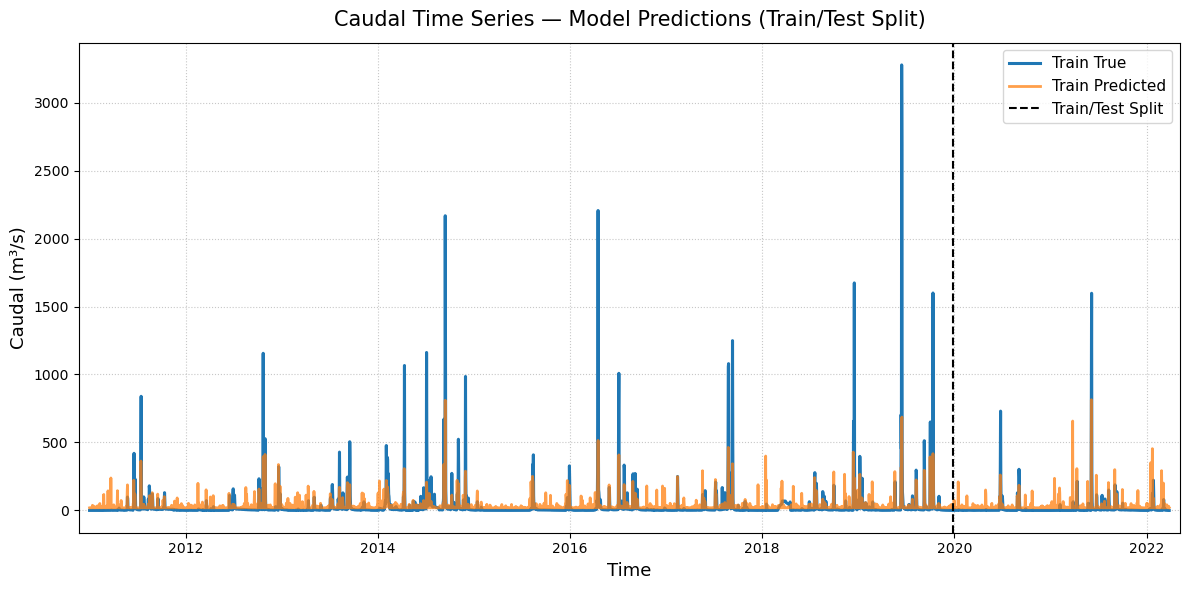

In [52]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

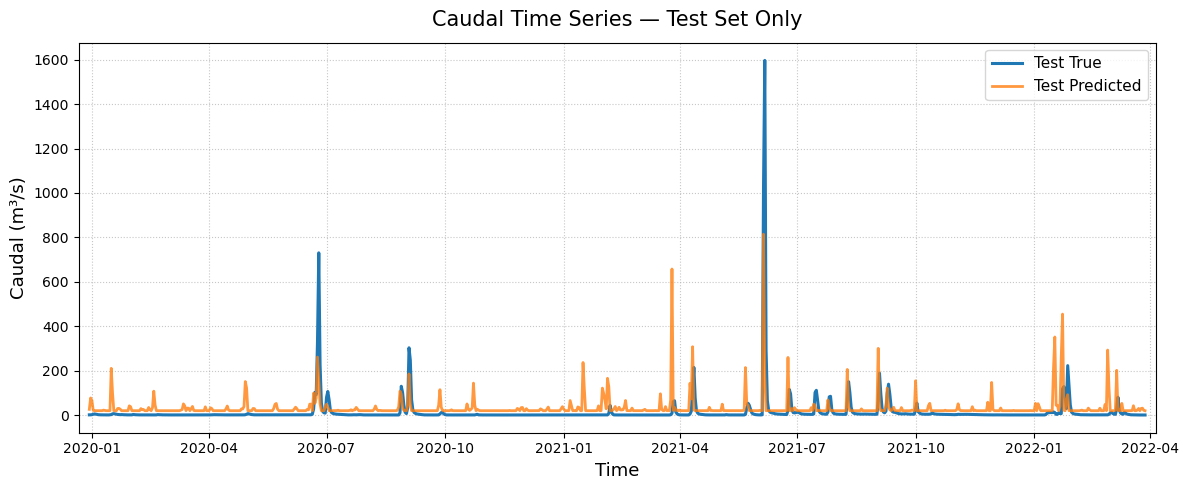

In [53]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()

plt.show()

## Graph

### Trial v3: With weights

In [54]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [56]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [2, 3, 4, 5, 6, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 2, 3, 4, 5, 6]
], dtype=torch.long)
edge_index

tensor([[2, 3, 4, 5, 6, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 2, 3, 4, 5, 6]])

In [57]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----
weights = torch.tensor(IDW_Calc(distances))

# Normalize to [0,1]

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[0.0546],
        [0.2744],
        [0.0833],
        [0.2472],
        [0.1759],
        [0.0201],
        [0.0458],
        [0.0278],
        [0.0422],
        [0.0286]], dtype=torch.float64)

In [58]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [59]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [60]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [61]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [62]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [63]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    if (window == 1):

        for t in range(T - window):
            # Input
            x_window = x_all[:,t,:].clone()  # shape: [num_nodes, window, num_features]

            # Don't use target as input (set it to zero)
            x_window[:, target_feature_idx] = 0

            # Target timestep
            y_full = x_all[:,t, target_feature_idx]  # shape: [num_nodes]
            
            # If: 
            #   target_node_idx = None --> Predict all variables
            #   target_node_idx = idx --> Predict 'idx' variable
            if target_node_idx is not None:
                y = y_full[target_node_idx]  # shape: scalar
            else:
                y = y_full  # shape: [num_nodes]

            data = Data(
                x=x_window,
                edge_index=edge_index,
                edge_weight=edge_weight,
                y=y
            )

            data_list.append(data)
    
    else:
        for t in range(T - window):

            # Input window
            x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

            # Don't use target as input (set it to zero)
            x_window[:, :, target_feature_idx] = 0

            # Target timestep
            y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
            
            # If: 
            #   target_node_idx = None --> Predict all variables
            #   target_node_idx = idx --> Predict 'idx' variable
            if target_node_idx is not None:
                y = y_full[target_node_idx]  # shape: scalar
            else:
                y = y_full  # shape: [num_nodes]

            data = Data(
                x=x_window,
                edge_index=edge_index,
                edge_weight=edge_weight,
                y=y
            )

            data_list.append(data)

    return data_list

In [64]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 1

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3283
Graph train: Data(x=[7, 10], edge_index=[2, 10], y=9.52135378611274e-05, edge_weight=[10, 1])
Length test: 820
Graph test: Data(x=[7, 10], edge_index=[2, 10], y=0.00010925142851192504, edge_weight=[10, 1])


### Model

In [65]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [67]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[1]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    all_preds_inv = []
    all_targets_inv = []

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

        y_pred = target_prediction.reshape(-1, 1).detach().clone()
        y_true = data.y.reshape(-1, 1).detach().clone()

        target_prediction_inv = scalerY.inverse_transform(y_pred)
        target_true_inv = scalerY.inverse_transform(y_true)

        all_preds_inv.append(torch.from_numpy(target_prediction_inv))
        all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_train_loss / len(train_loader)

    return avg_loss, nse

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [69]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )
if use_weigths:
    torch.save(model, 'v2/models/BasicGNN_Arq2_weigths.pth')
else:
    torch.save(model, 'v2/models/BasicGNN_Arq2_noweigths.pth')

Epoch [001/200] | Train Loss: 0.001389 | Train NSE: 0.12 | Test Loss: 0.000718 | Test NSE: -0.32
Epoch [002/200] | Train Loss: 0.001386 | Train NSE: 0.12 | Test Loss: 0.000738 | Test NSE: -0.35
Epoch [003/200] | Train Loss: 0.001386 | Train NSE: 0.12 | Test Loss: 0.000749 | Test NSE: -0.37
Epoch [004/200] | Train Loss: 0.001386 | Train NSE: 0.12 | Test Loss: 0.000754 | Test NSE: -0.38
Epoch [005/200] | Train Loss: 0.001386 | Train NSE: 0.12 | Test Loss: 0.000757 | Test NSE: -0.39
Epoch [006/200] | Train Loss: 0.001387 | Train NSE: 0.12 | Test Loss: 0.000759 | Test NSE: -0.39
Epoch [007/200] | Train Loss: 0.001387 | Train NSE: 0.12 | Test Loss: 0.000762 | Test NSE: -0.40
Epoch [008/200] | Train Loss: 0.001387 | Train NSE: 0.12 | Test Loss: 0.000764 | Test NSE: -0.40
Epoch [009/200] | Train Loss: 0.001387 | Train NSE: 0.12 | Test Loss: 0.000766 | Test NSE: -0.40
Epoch [010/200] | Train Loss: 0.001387 | Train NSE: 0.12 | Test Loss: 0.000767 | Test NSE: -0.40
Epoch [011/200] | Train Loss: 

In [71]:
from captum.attr import IntegratedGradients
import numpy as np
import torch
import matplotlib.pyplot as plt


def explain_with_captum(model, test_loader, variable_order):

    model.eval()
    all_attr = []

    print("\nRunning Captum Integrated Gradients...")

    for batch in test_loader:

        x = batch.x.clone().detach().requires_grad_(True)
        edge_index = batch.edge_index

        ########################################
        # IMPORTANT: wrap model correctly
        ########################################
        def forward_func(x_input):
            return model(x_input, edge_index)

        ig = IntegratedGradients(forward_func)

        attributions = ig.attribute(
            inputs=x
        )

        print("Batch attribution shape:", attributions.shape)

        attr = attributions.detach().cpu().numpy()
        attr = np.abs(attr)

        all_attr.append(attr)

    ##################################
    # Merge batches
    ##################################
    attr = np.concatenate(all_attr, axis=0)

    print("Merged attribution shape:", attr.shape)

    ##################################
    # Reduce feature dimension
    ##################################
    #attr = attr.mean(axis=0) 

    print("Reduced shape:", attr.shape)

    return attr

In [72]:
attr = explain_with_captum(model,test_loader, variable_order)


Running Captum Integrated Gradients...
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([448, 10])
Batch attribution shape: torch.Size([364, 10])
Merged attribution shape: (5740, 10)
Reduced shape: (5740, 10)


In [73]:
def clean_list(lst):
    pattern = r'\([^)]*\)|\[[^\]]*\]|\{[^}]*\}|<[^>]*>'
    
    cleaned = []
    for s in lst:
        # remove bracket contents
        s = re.sub(pattern, '', s)
        # collapse multiple spaces + trim
        s = re.sub(r'\s+', ' ', s).strip()
        cleaned.append(s)
    
    return cleaned

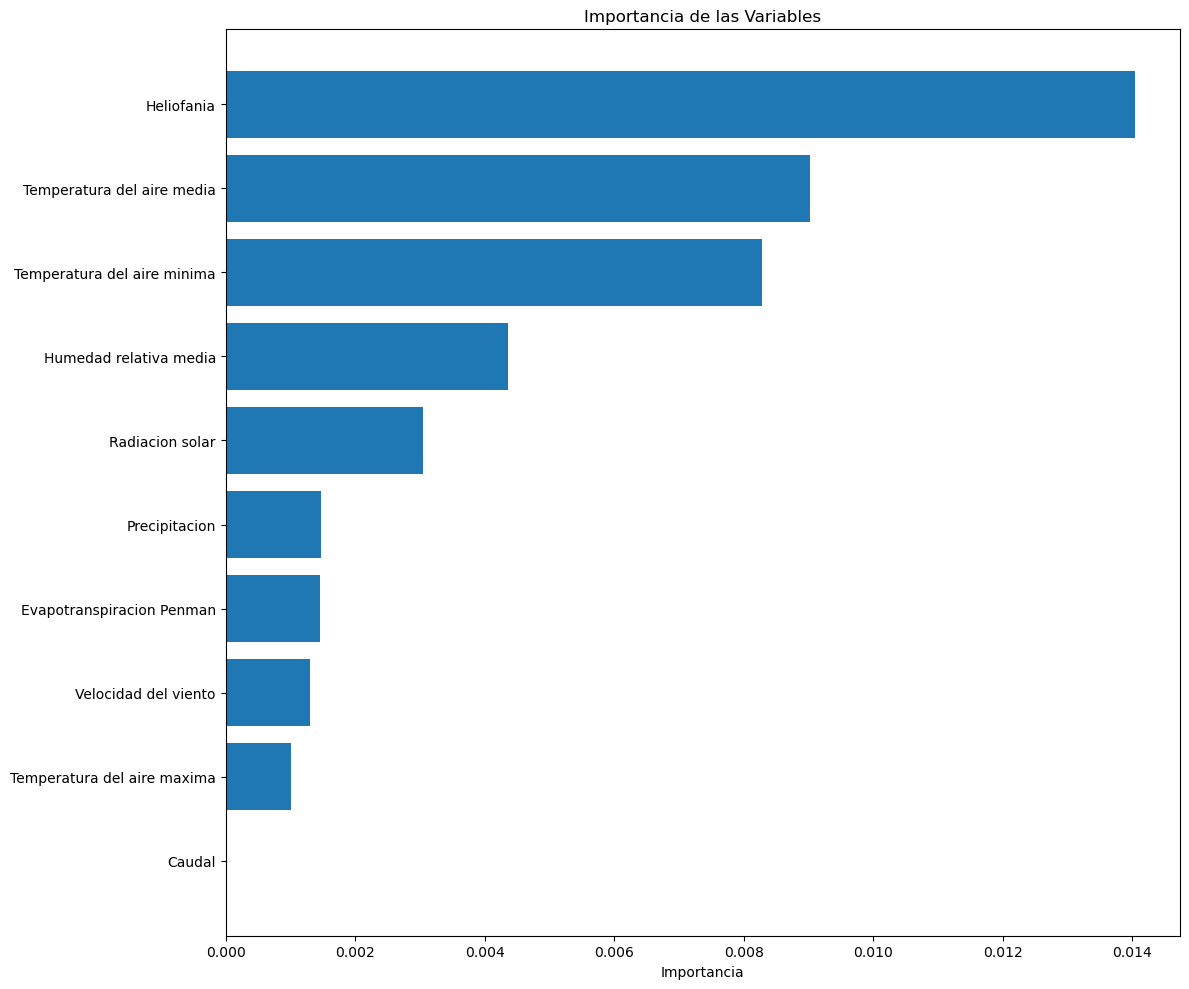

In [74]:
import numpy as np
import matplotlib.pyplot as plt

node_importance = attr.mean(axis=0)
var_names = clean_list(variable_order)

# sort (optional but often makes interpretation easier)
idx = np.argsort(node_importance)
node_importance = node_importance[idx]
var_names = np.array(var_names)[idx]

plt.figure(figsize=(12, 10))
plt.barh(np.arange(len(node_importance)), node_importance)

plt.yticks(np.arange(len(node_importance)), var_names)
plt.xlabel("Importancia")
plt.title("Importancia de las Variables")

plt.tight_layout()
plt.show()

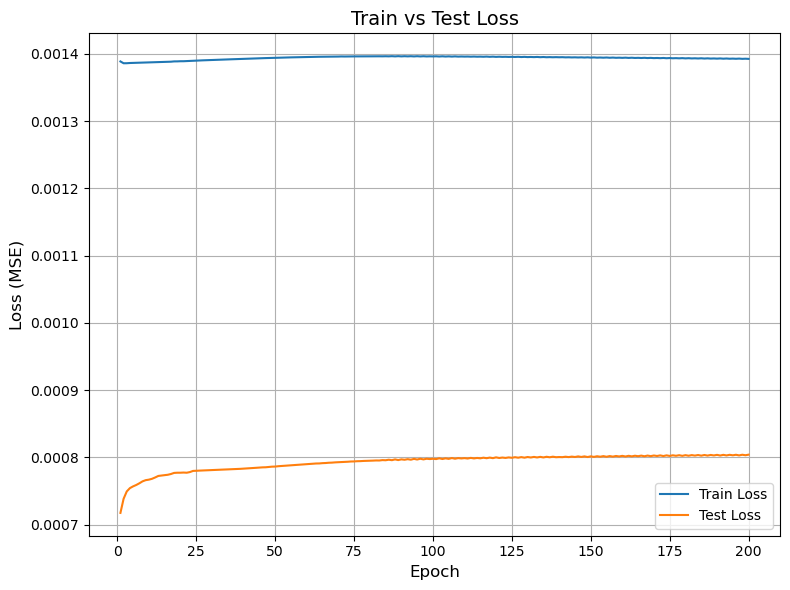

In [75]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

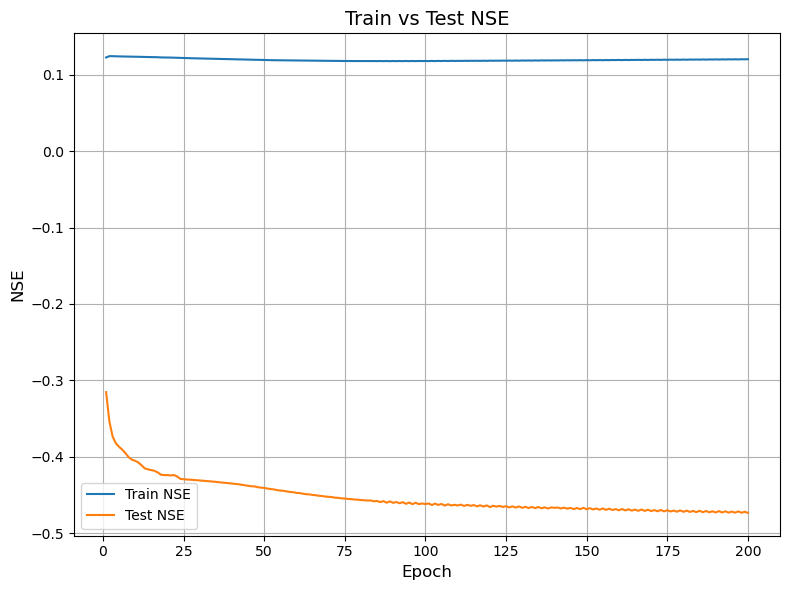

In [76]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [77]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

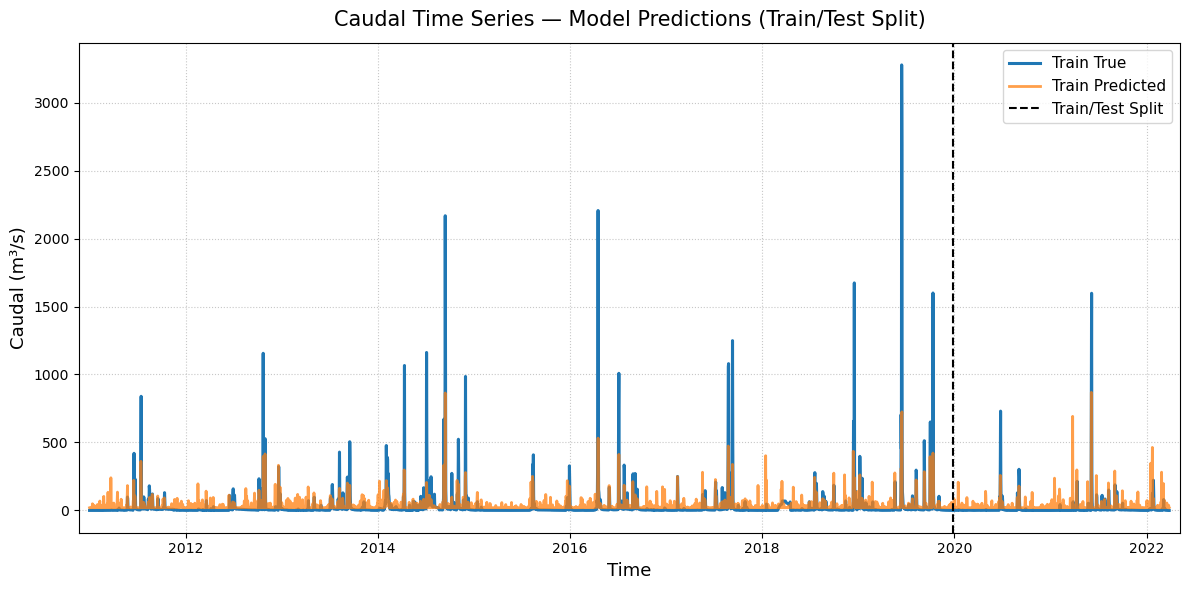

In [78]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

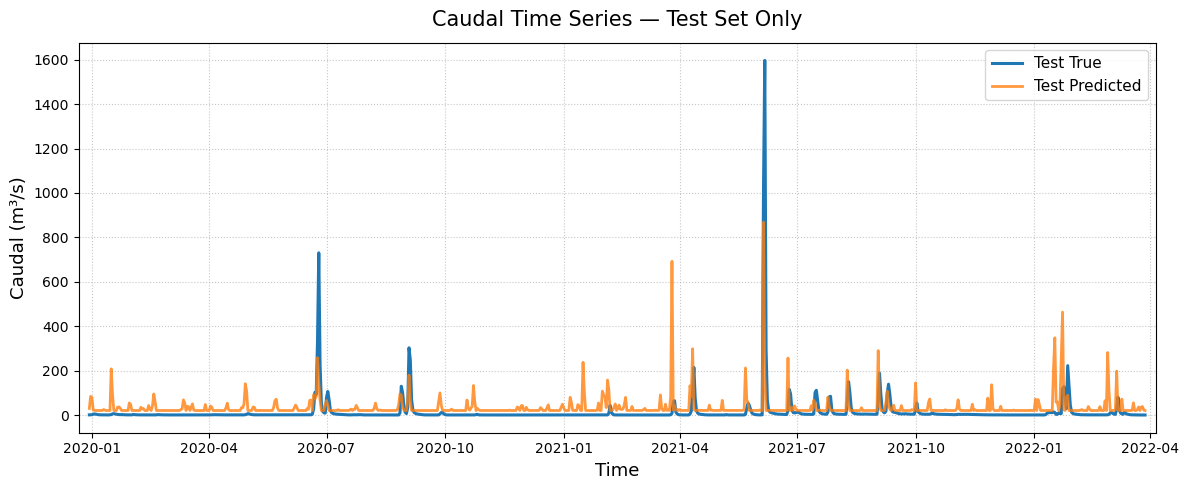

In [79]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()

plt.show()

## Grafo

### Trial 4: Metodo Angela y Self Loop

In [365]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [366]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]
], dtype=torch.long)
edge_index

tensor([[0, 2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]])

In [367]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

sigma = distances.mean()

weights = torch.exp(
    - (distances ** 2) / (2 * sigma ** 2)
)

# Normalize to [0,1]
weights = (weights - weights.min()) / (
    weights.max() - weights.min()
)

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[1.0000],
        [0.3984],
        [1.0000],
        [0.9584],
        [0.5591],
        [0.8290],
        [0.7662],
        [0.0000],
        [0.5037],
        [0.3256],
        [0.1158],
        [0.2904],
        [0.1271]])

In [368]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [369]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [370]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [371]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [374]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [375]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        # Self loop --> Use target as input (don't make feature zeros!)
        #x_window[:, :, target_feature_idx] = 0

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [376]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[8, 36, 10], edge_index=[2, 13], y=4.089299181941897e-05, edge_weight=[13, 1])
Length test: 785
Graph test: Data(x=[8, 36, 10], edge_index=[2, 13], y=0.0004632504715118557, edge_weight=[13, 1])


### Model

In [377]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [378]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [379]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

    return total_train_loss / len(train_loader)

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [380]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'models/BasicGNN_Arq4_weigths.pth')
else:
    torch.save(model, 'models/BasicGNN_Arq4_noweigths.pth')

Epoch [001/200] | Train Loss: 0.002927 | Test Loss: 0.000702 | Test NSE: -0.27
Epoch [002/200] | Train Loss: 0.001479 | Test Loss: 0.000593 | Test NSE: -0.07
Epoch [003/200] | Train Loss: 0.001016 | Test Loss: 0.000516 | Test NSE: 0.07
Epoch [004/200] | Train Loss: 0.000765 | Test Loss: 0.000512 | Test NSE: 0.06
Epoch [005/200] | Train Loss: 0.000696 | Test Loss: 0.000515 | Test NSE: 0.05
Epoch [006/200] | Train Loss: 0.000665 | Test Loss: 0.000508 | Test NSE: 0.07
Epoch [007/200] | Train Loss: 0.000638 | Test Loss: 0.000503 | Test NSE: 0.07
Epoch [008/200] | Train Loss: 0.000615 | Test Loss: 0.000502 | Test NSE: 0.07
Epoch [009/200] | Train Loss: 0.000596 | Test Loss: 0.000504 | Test NSE: 0.07
Epoch [010/200] | Train Loss: 0.000581 | Test Loss: 0.000510 | Test NSE: 0.06
Epoch [011/200] | Train Loss: 0.000567 | Test Loss: 0.000517 | Test NSE: 0.05
Epoch [012/200] | Train Loss: 0.000555 | Test Loss: 0.000525 | Test NSE: 0.03
Epoch [013/200] | Train Loss: 0.000544 | Test Loss: 0.000534 |

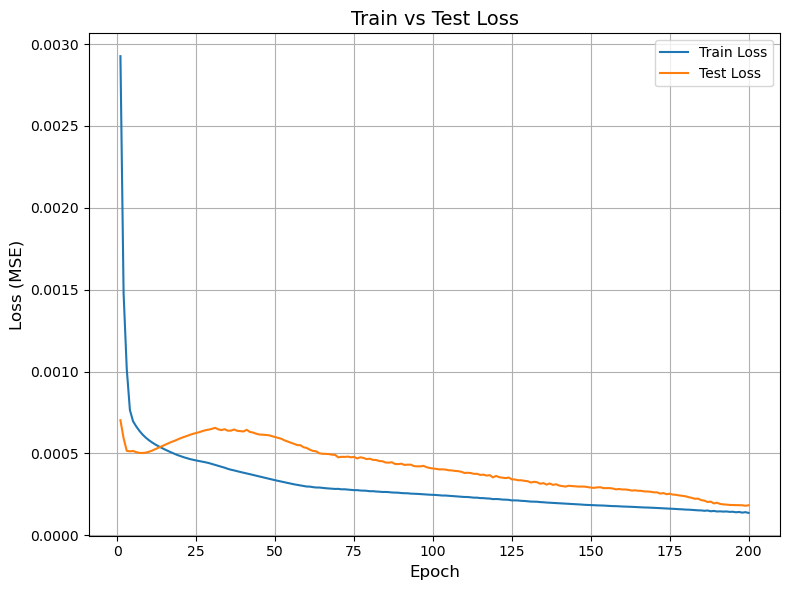

In [382]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
#plt.ylim((0,max(test_loss_list)))

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

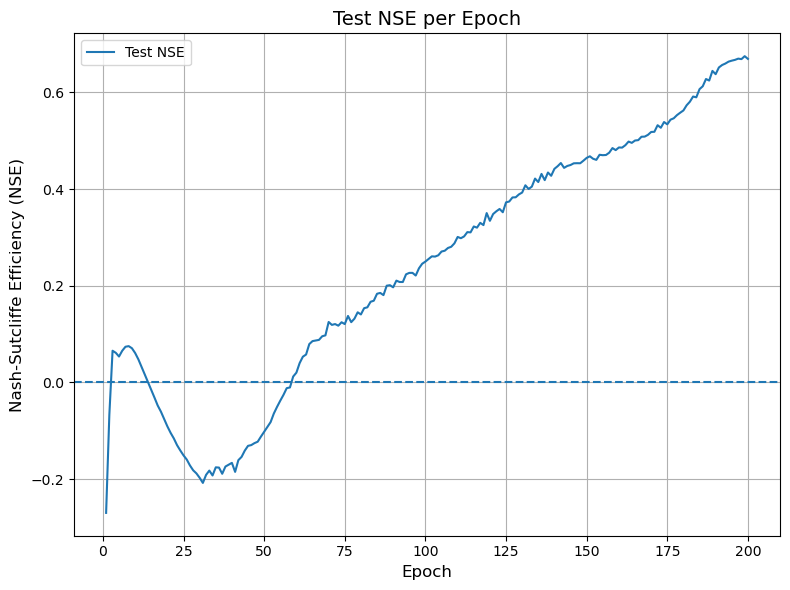

In [383]:
plt.figure(figsize=(8,6))

plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Nash-Sutcliffe Efficiency (NSE)", fontsize=12)
plt.title("Test NSE per Epoch", fontsize=14)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.axhline(0, linestyle="--")  # useful NSE reference

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [384]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

In [386]:
nse_metric(y_true_test, y_pred_test)

0.6692459353340776

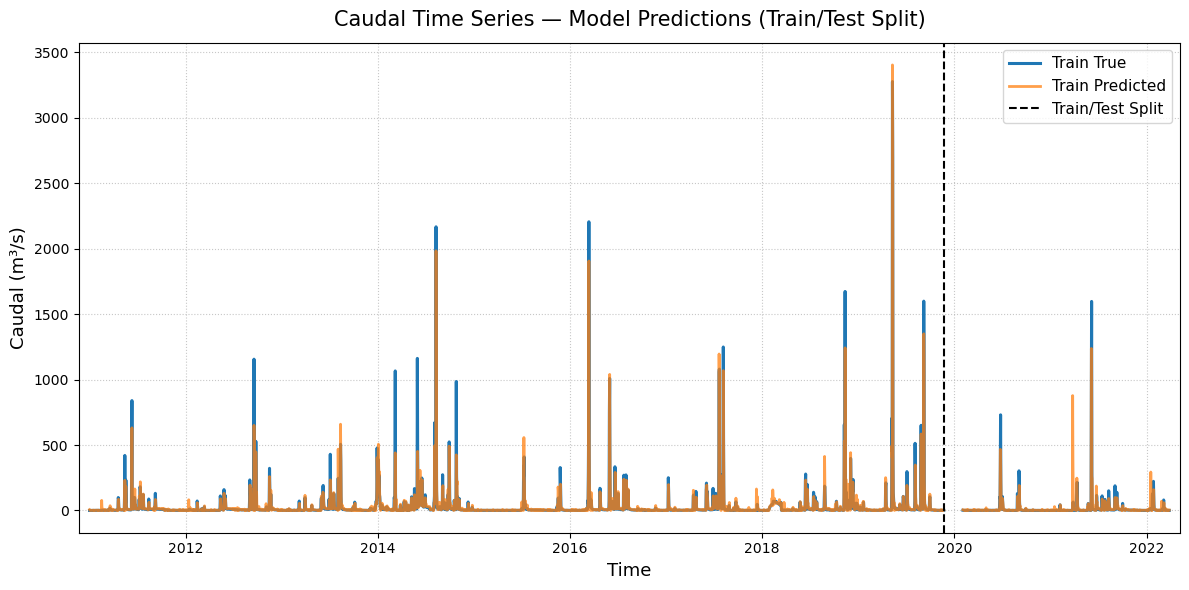

In [385]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()

## Graph

### Trail 4 v2: Angela, Self Loops y Weights

In [387]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [388]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]
], dtype=torch.long)
edge_index

tensor([[0, 2, 3, 4, 5, 6, 7, 1, 1, 1, 1, 1, 1],
        [0, 0, 0, 0, 0, 0, 0, 2, 3, 4, 5, 6, 7]])

In [389]:
# --- (3) Se calculan las distancias de los nodos ---

row, col = edge_index

coords = torch.tensor(coords_list, dtype=torch.float)

distances = torch.linalg.norm(
    coords[row] - coords[col],
    dim=1
)


# ---- Prevent extremely small distances ----

min_dist = distances.quantile(0.1)  # 10th percentile
distances = torch.clamp(distances, min=min_dist)

# ---- Gaussian weighting ----

sigma = distances.mean()

weights = torch.exp(
    - (distances ** 2) / (2 * sigma ** 2)
)

# Normalize to [0,1]
weights = (weights - weights.min()) / (
    weights.max() - weights.min()
)

dist_weight = weights.view(-1, 1)
dist_weight

tensor([[1.0000],
        [0.3984],
        [1.0000],
        [0.9584],
        [0.5591],
        [0.8290],
        [0.7662],
        [0.0000],
        [0.5037],
        [0.3256],
        [0.1158],
        [0.2904],
        [0.1271]])

In [390]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [391]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [392]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [393]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [394]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [395]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    edge_weight=None,          # [num_nodes, num_features]
    window=12,
    target_feature_idx=0,      # feature to predict
    target_node_idx=None       # None → predict for all nodes
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        # Self loop --> Use target as input (don't make feature zeros!)
        #x_window[:, :, target_feature_idx] = 0

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [396]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    edge_weight,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[8, 36, 10], edge_index=[2, 13], y=4.089299181941897e-05, edge_weight=[13, 1])
Length test: 785
Graph test: Data(x=[8, 36, 10], edge_index=[2, 13], y=0.0004632504715118557, edge_weight=[13, 1])


### Model

In [398]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [399]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [400]:
from sklearn.metrics import r2_score as nse_metric

num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        # print(f"X: {data.x.shape}")
        # print(f"edge_index: {data.edge_index.shape}")
        # print(f"edge_weight: {data.edge_weight.shape}")
        # print(f"y: {data.y.shape}")

        #print(data.edge_weight)

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        # print(f"target shape out: {target_prediction.shape}")
        # print(f"target out: {target_prediction}")

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

    return total_train_loss / len(train_loader)

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            #print(out.shape)
            #print(out)

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0
            #print(f"Despues: {(target_prediction_inv<0).sum()}")

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [401]:
num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'models/BasicGNN_Arq4_weigths.pth')
else:
    torch.save(model, 'models/BasicGNN_Arq4_noweigths.pth')

Epoch [001/200] | Train Loss: 0.004992 | Test Loss: 0.000824 | Test NSE: -0.48
Epoch [002/200] | Train Loss: 0.001672 | Test Loss: 0.000597 | Test NSE: -0.09
Epoch [003/200] | Train Loss: 0.001608 | Test Loss: 0.000593 | Test NSE: -0.08
Epoch [004/200] | Train Loss: 0.001576 | Test Loss: 0.000592 | Test NSE: -0.08
Epoch [005/200] | Train Loss: 0.001542 | Test Loss: 0.000594 | Test NSE: -0.08
Epoch [006/200] | Train Loss: 0.001502 | Test Loss: 0.000595 | Test NSE: -0.08
Epoch [007/200] | Train Loss: 0.001452 | Test Loss: 0.000592 | Test NSE: -0.07
Epoch [008/200] | Train Loss: 0.001383 | Test Loss: 0.000580 | Test NSE: -0.05
Epoch [009/200] | Train Loss: 0.001291 | Test Loss: 0.000546 | Test NSE: 0.01
Epoch [010/200] | Train Loss: 0.001181 | Test Loss: 0.000485 | Test NSE: 0.12
Epoch [011/200] | Train Loss: 0.001061 | Test Loss: 0.000415 | Test NSE: 0.25
Epoch [012/200] | Train Loss: 0.000953 | Test Loss: 0.000368 | Test NSE: 0.33
Epoch [013/200] | Train Loss: 0.000873 | Test Loss: 0.00

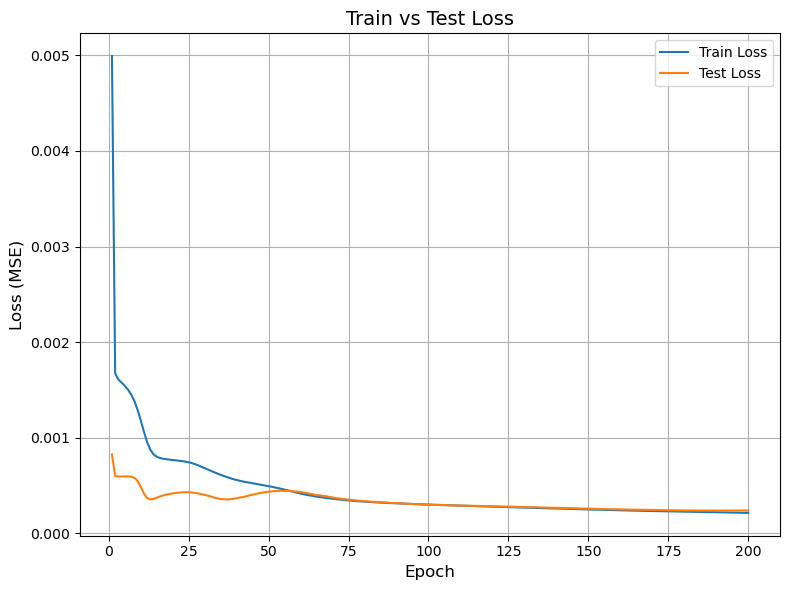

In [402]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
#plt.ylim((0,max(test_loss_list)))

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

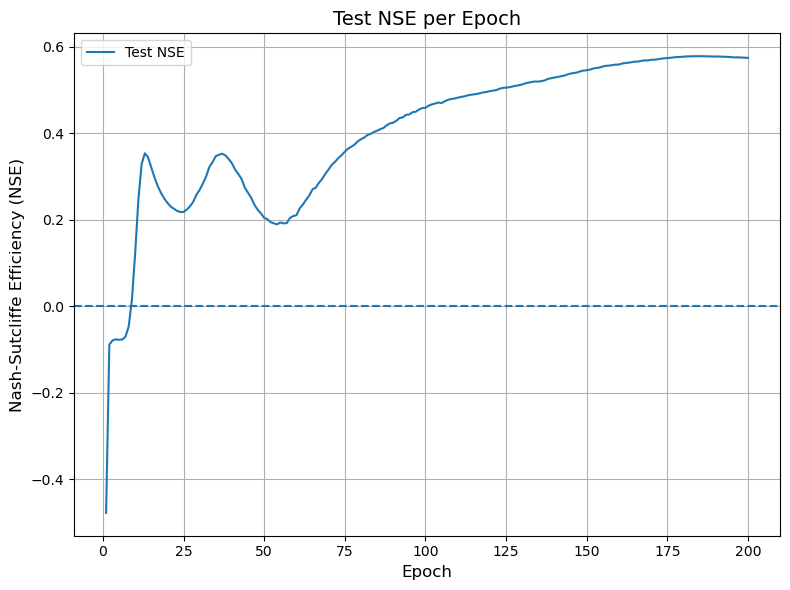

In [403]:
plt.figure(figsize=(8,6))

plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Nash-Sutcliffe Efficiency (NSE)", fontsize=12)
plt.title("Test NSE per Epoch", fontsize=14)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.axhline(0, linestyle="--")  # useful NSE reference

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()

In [404]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

In [407]:
nse_metric(y_true_test, y_pred_test)

0.5737745949158279

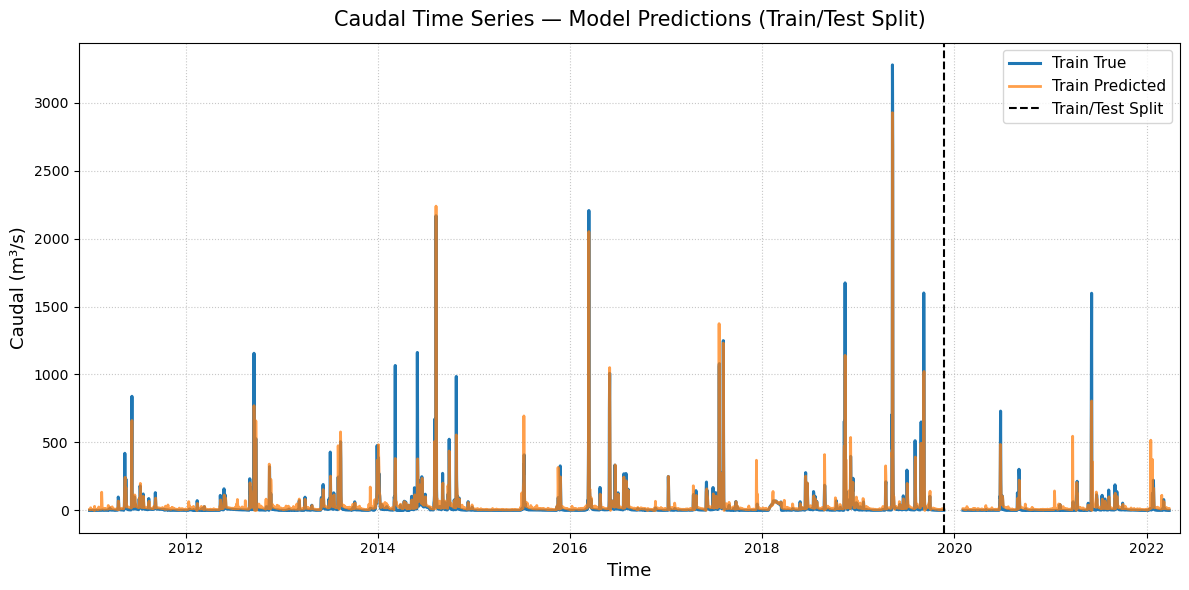

In [406]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
plt.show()